# Chapter 4 Empirical Analysis

This notebook implements the **machine-learning and model-comparison components** of **Chapter 4**, aligned with the revised methodology described in **Chapter 3** (return construction, realised volatility proxy, rolling walk-forward forecasting, QLIKE evaluation, and multi-model comparison via SPA and MCS).

The **GARCH-family estimation and diagnostics** (GARCH, IGARCH, and GARCH-X) are produced in the companion **RMarkdown pipeline**, and the resulting parameter estimates and rolling forecasts are imported here for evaluation and hybrid modelling.

## Models covered in this notebook

1. **Random Forest (RF)** one-step-ahead volatility forecasts using lagged returns, volume, rolling volatility features, and sentiment lags
2. **RF + Sentiment** (explicit sentiment predictors included)
3. **Hybrid RF** augmented with **walk-forward GARCH/IGARCH conditional volatility forecasts** as an additional feature (**no look-ahead**, only information available at time (t))

> **Note:** GARCH/IGARCH and GARCH-X variance forecasts are treated as benchmark inputs generated from the R pipeline, ensuring consistent rolling estimation design across econometric and ML models.

## Forecasting design

* **One-step-ahead** forecasts
* **Rolling-window (walk-forward)** estimation and forecasting
* Rolling window length is configurable and applied consistently across models

## Evaluation

* Primary loss: **QLIKE** (Patton-style) evaluated against the realised volatility proxy (RV_t) used in Chapter 4
* Benchmark comparisons via **loss differentials**
* Multiple-model inference via **block bootstrap SPA** and **Model Confidence Set (MCS)**

## Reproducibility

This notebook is intended to run end-to-end. If you move data files, update `MERGED_FILE` (and any imported GARCH forecast file paths) in the configuration cell.


In [313]:
# ============================================
# IMPORT + ALIGN R GARCH-FAMILY OUTPUTS
# ============================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path

# --------------------------------------------
# Paths
# --------------------------------------------
DATA_DIR = Path("../Data")
MERGED_FILE = DATA_DIR / "final_data.csv"

OUT_DIR = Path("./outputs")
TABLE_DIR = OUT_DIR / "tables"
FIG_DIR = OUT_DIR / "figures"

GARCH_FAMILY_DIR = Path("./garch_family")
R_FORECAST_FILE = GARCH_FAMILY_DIR / "garch_family_oos_forecasts_from_r.csv"
R_PARAM_FILE = GARCH_FAMILY_DIR / "garch_family_params_from_r.csv"
R_DIAG_BASELINE_FILE = GARCH_FAMILY_DIR / "garch_family_baseline_diagnostics_from_r.csv"
R_DIAG_SENTIMENT_FILE = GARCH_FAMILY_DIR / "garch_family_sentiment_diagnostics_from_r.csv"
R_ARCHLM_FILE = GARCH_FAMILY_DIR / "garch_family_archlm_from_r.csv"

OUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------
# Helpers
# --------------------------------------------
def parse_date_column(s: pd.Series) -> pd.Series:
    """
    Robust date parsing to mirror the Rmd logic as closely as possible.
    """
    s1 = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    s2 = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    out = s1.fillna(s2)
    if out.isna().any():
        bad = s[out.isna()].head(10).tolist()
        raise ValueError(f"Date parsing failed for some rows. Examples: {bad}")
    return out


def assert_unique_monotonic_dates(df: pd.DataFrame, name: str) -> None:
    if "Date" not in df.columns:
        raise KeyError(f"{name} has no 'Date' column.")
    if df["Date"].duplicated().any():
        dups = df.loc[df["Date"].duplicated(), "Date"].astype(str).tolist()[:10]
        raise ValueError(f"{name} has duplicate Date values. Examples: {dups}")
    if not df["Date"].is_monotonic_increasing:
        raise ValueError(f"{name} Date is not sorted ascending.")


# --------------------------------------------
# 1. Load raw thesis data
# --------------------------------------------
df = pd.read_csv(MERGED_FILE)
df["Date"] = parse_date_column(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Standardise sentiment column to match Rmd
if "Trends" in df.columns and "Search_Interest" not in df.columns:
    df["Search_Interest"] = df["Trends"]

# Log returns in percent, matching R:
# r = 100 * (log(Close) - log(lag(Close)))
df["r"] = 100 * (np.log(df["Close"]) - np.log(df["Close"].shift(1)))

# Drop the first NA return row
df = df.loc[df["r"].notna()].copy()

# Create lagged sentiment, matching Rmd:
# Search_Interest_lag = lag(Search_Interest)
if "Search_Interest" not in df.columns:
    raise KeyError("Neither 'Search_Interest' nor 'Trends' found in final_data.csv.")

df["Search_Interest_lag"] = df["Search_Interest"].shift(1)

# Drop rows made invalid by lagging sentiment
# This is the effective sample used by GARCH-X / IGARCH-X in the Rmd
df_model = df.loc[df["Search_Interest_lag"].notna()].copy().reset_index(drop=True)

assert_unique_monotonic_dates(df_model, "df_model")

print("Effective modelling sample rebuilt in Python.")
print("Date range:", df_model["Date"].min().date(), "to", df_model["Date"].max().date())
print("Rows:", len(df_model))

# --------------------------------------------
# 2. Recreate the OOS split used in the Rmd
# --------------------------------------------
TEST_SIZE = 0.20
N = len(df_model)
split_idx = int(np.floor((1 - TEST_SIZE) * N))
n_oos = N - split_idx

oos_dates_python = df_model.loc[split_idx:, "Date"].reset_index(drop=True)
realized_var_python = (df_model.loc[split_idx:, "r"] ** 2).reset_index(drop=True)

oos_reference = pd.DataFrame({
    "Date": oos_dates_python,
    "Realized_Variance_Python": realized_var_python
})

assert_unique_monotonic_dates(oos_reference, "oos_reference")

print("\nPython OOS reference:")
print("Split index:", split_idx)
print("OOS rows:", len(oos_reference))
print("OOS range:", oos_reference["Date"].min().date(), "to", oos_reference["Date"].max().date())

# --------------------------------------------
# 3. Load R forecast file
# --------------------------------------------
r_fc = pd.read_csv(R_FORECAST_FILE)
r_fc["Date"] = parse_date_column(r_fc["Date"])
r_fc = r_fc.sort_values("Date").reset_index(drop=True)

assert_unique_monotonic_dates(r_fc, "r_fc")

expected_forecast_cols = [
    "Realized_Variance",
    "GARCH_Normal",
    "GARCH_Student_t",
    "GARCHX_Normal",
    "GARCHX_Student_t",
    "IGARCH_Normal",
    "IGARCH_Student_t",
    "IGARCHX_Normal",
    "IGARCHX_Student_t",
]
missing_cols = [c for c in expected_forecast_cols if c not in r_fc.columns]
if missing_cols:
    raise KeyError(f"R forecast file is missing columns: {missing_cols}")

print("\nR forecast file loaded.")
print("Rows:", len(r_fc))
print("Range:", r_fc["Date"].min().date(), "to", r_fc["Date"].max().date())

# --------------------------------------------
# 4. Strict alignment check: Python OOS vs R OOS
# --------------------------------------------
if len(r_fc) != len(oos_reference):
    print("\nWARNING: Row counts differ.")
    print("R forecast rows:", len(r_fc))
    print("Python OOS rows:", len(oos_reference))

# Compare normalized numpy arrays, not Series.equals()
dates_r = pd.to_datetime(r_fc["Date"]).dt.normalize().to_numpy()
dates_py = pd.to_datetime(oos_reference["Date"]).dt.normalize().to_numpy()

same_dates_in_order = (
    len(dates_r) == len(dates_py)
    and np.array_equal(dates_r, dates_py)
)

if same_dates_in_order:
    print("\nDate alignment check: PASSED (same dates in same order).")
else:
    print("\nDate alignment check: NOT identical in-order.")
    
    merged_dates = r_fc[["Date"]].merge(
        oos_reference[["Date"]],
        on="Date",
        how="outer",
        indicator=True
    )
    print(merged_dates["_merge"].value_counts(dropna=False))
    
    mismatch_idx = np.where(dates_r != dates_py)[0]
    if len(mismatch_idx) > 0:
        print("\nFirst mismatches:")
        for j in mismatch_idx[:10]:
            print(
                f"Row {j}: R = {r_fc['Date'].iloc[j]} | Python = {oos_reference['Date'].iloc[j]}"
            )
    else:
        print("\nNo actual date mismatches found; likely dtype/precision issue only.")

print("R date dtype:", r_fc["Date"].dtype)
print("Python date dtype:", oos_reference["Date"].dtype)

# --------------------------------------------
# 5. Merge on Date only
# --------------------------------------------
eval_df = oos_reference.merge(
    r_fc,
    on="Date",
    how="inner",
    validate="one_to_one"
).sort_values("Date").reset_index(drop=True)

# --------------------------------------------
# 6. Check realised variance consistency
# --------------------------------------------
eval_df["rv_diff"] = eval_df["Realized_Variance_Python"] - eval_df["Realized_Variance"]
max_abs_diff = eval_df["rv_diff"].abs().max()

print("\nRealized variance consistency:")
print("Max absolute difference:", max_abs_diff)

if max_abs_diff < 1e-10:
    print("Realized variance check: PASSED")
else:
    print("Realized variance check: NOT PASSED")
    print(eval_df.loc[eval_df["rv_diff"].abs() > 1e-10,
                      ["Date", "Realized_Variance_Python", "Realized_Variance", "rv_diff"]].head(10))

# Master target
eval_df["Realized"] = eval_df["Realized_Variance_Python"]

# --------------------------------------------
# 7. Final forecast dictionary for evaluation
# --------------------------------------------
forecast_cols = [
    "GARCH_Normal",
    "GARCH_Student_t",
    "GARCHX_Normal",
    "GARCHX_Student_t",
    "IGARCH_Normal",
    "IGARCH_Student_t",
    "IGARCHX_Normal",
    "IGARCHX_Student_t",
]

forecast_dict = {col: eval_df[col].copy() for col in forecast_cols}

print("\nFinal evaluation frame ready.")
print("Shape:", eval_df.shape)
print("Date range:", eval_df["Date"].min().date(), "to", eval_df["Date"].max().date())
print("\nHead:")
print(eval_df[["Date", "Realized"] + forecast_cols].head())
print("\nTail:")
print(eval_df[["Date", "Realized"] + forecast_cols].tail())

# --------------------------------------------
# 8. Optional: load parameter and diagnostic files
# --------------------------------------------
garch_params_r = pd.read_csv(R_PARAM_FILE) if R_PARAM_FILE.exists() else pd.DataFrame()
garch_diag_baseline_r = pd.read_csv(R_DIAG_BASELINE_FILE) if R_DIAG_BASELINE_FILE.exists() else pd.DataFrame()
garch_diag_sentiment_r = pd.read_csv(R_DIAG_SENTIMENT_FILE) if R_DIAG_SENTIMENT_FILE.exists() else pd.DataFrame()
garch_archlm_r = pd.read_csv(R_ARCHLM_FILE) if R_ARCHLM_FILE.exists() else pd.DataFrame()

print("\nAuxiliary R outputs:")
print("Params rows:", len(garch_params_r))
print("Baseline diagnostics rows:", len(garch_diag_baseline_r))
print("Sentiment diagnostics rows:", len(garch_diag_sentiment_r))
print("ARCH-LM rows:", len(garch_archlm_r))

Effective modelling sample rebuilt in Python.
Date range: 2017-01-03 to 2025-08-09
Rows: 3141

Python OOS reference:
Split index: 2512
OOS rows: 629
OOS range: 2023-11-20 to 2025-08-09

R forecast file loaded.
Rows: 629
Range: 2023-11-20 to 2025-08-09

Date alignment check: PASSED (same dates in same order).
R date dtype: datetime64[us]
Python date dtype: datetime64[s]

Realized variance consistency:
Max absolute difference: 7.105427357601002e-15
Realized variance check: PASSED

Final evaluation frame ready.
Shape: (629, 13)
Date range: 2023-11-20 to 2025-08-09

Head:
        Date   Realized  GARCH_Normal  GARCH_Student_t  GARCHX_Normal  \
0 2023-11-20   0.058338      4.906703         9.431624       4.906699   
1 2023-11-21  20.604901      4.778366         8.663161       4.778105   
2 2023-11-22  19.537628      5.137439         9.848868       5.137433   
3 2023-11-23   0.145924      5.496478        11.363585       5.496540   
4 2023-11-24   1.318566      5.344907        10.304499      

In [314]:
print(type(df_oos))
print(df_oos.shape)
print(df_oos.index[:10])
print(df_oos.index[-10:])
print(df_oos.columns.tolist())
print("eval_df rows:", len(eval_df))
print("eval_df date min:", eval_df["Date"].min())
print("eval_df date max:", eval_df["Date"].max())

print("df_oos rows:", len(df_oos))
print("df_oos index min:", df_oos.index.min())
print("df_oos index max:", df_oos.index.max())

<class 'pandas.DataFrame'>
(629, 10)
DatetimeIndex(['2023-11-20', '2023-11-21', '2023-11-22', '2023-11-23',
               '2023-11-24', '2023-11-25', '2023-11-26', '2023-11-27',
               '2023-11-28', '2023-11-29'],
              dtype='datetime64[us]', name='Date', freq=None)
DatetimeIndex(['2025-07-31', '2025-08-01', '2025-08-02', '2025-08-03',
               '2025-08-04', '2025-08-05', '2025-08-06', '2025-08-07',
               '2025-08-08', '2025-08-09'],
              dtype='datetime64[us]', name='Date', freq=None)
['Open', 'Close', 'Volume', 'Search_Interest', 'log_return', 'sq_return', 'abs_return', 'RV', 'log_volume', 'Search_Interest_lag']
eval_df rows: 629
eval_df date min: 2023-11-20 00:00:00
eval_df date max: 2025-08-09 00:00:00
df_oos rows: 629
df_oos index min: 2023-11-20 00:00:00
df_oos index max: 2025-08-09 00:00:00


## 4.0: Load data and harmonize columns

Expected columns (minimum):
- `Date`
- `Close`
- `Volume`
- `Search_Interest` (or `Trends` which will be renamed)

The sample is then sorted, indexed by Date, and checked for missing values.


In [315]:
# =========================
# 1. Load data
# =========================

from pathlib import Path
import pandas as pd


def load_data(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    df = pd.read_csv(path)

    # -------------------------
    # Validate Date column
    # -------------------------
    if "Date" not in df.columns:
        raise ValueError("Dataset must contain a 'Date' column.")

    # -------------------------
    # Parse dates robustly
    # Match the R logic as closely as possible:
    # try dd/mm/YYYY first, then YYYY-mm-dd
    # -------------------------
    d1 = pd.to_datetime(df["Date"], format="%d/%m/%Y", errors="coerce")
    d2 = pd.to_datetime(df["Date"], format="%Y-%m-%d", errors="coerce")
    df["Date"] = d1.fillna(d2)

    if df["Date"].isna().any():
        bad_examples = df.loc[df["Date"].isna(), "Date"].head(10).tolist()
        raise ValueError(f"Date parsing failed for some rows. Examples: {bad_examples}")

    # -------------------------
    # Rename sentiment column if needed
    # -------------------------
    if "Trends" in df.columns and "Search_Interest" not in df.columns:
        df = df.rename(columns={"Trends": "Search_Interest"})

    # -------------------------
    # Validate required columns
    # -------------------------
    required_cols = ["Close", "Volume", "Search_Interest"]
    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Missing required column: {col}")

    # -------------------------
    # Ensure numeric types
    # -------------------------
    for col in required_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Drop rows with missing required inputs
    df = df.dropna(subset=required_cols).copy()

    # -------------------------
    # Set index and sort
    # -------------------------
    df = df.set_index("Date").sort_index()

    # -------------------------
    # Duplicate & ordering checks
    # -------------------------
    if df.index.duplicated().any():
        dupes = df.index[df.index.duplicated()].unique()[:10]
        raise ValueError(f"Duplicate dates detected in dataset. Examples: {list(dupes)}")

    if not df.index.is_monotonic_increasing:
        raise ValueError("Date index is not strictly increasing.")

    # -------------------------
    # Basic frequency check
    # -------------------------
    inferred_freq = pd.infer_freq(df.index)

    print(f"Loaded {len(df)} observations")
    print(f"Sample: {df.index.min().date()} → {df.index.max().date()}")
    print(f"Inferred frequency: {inferred_freq}")

    if inferred_freq is None:
        print("Warning: Could not infer regular frequency (possible missing dates).")

    return df


# -------------------------
# Execute loading
# -------------------------

df_raw = load_data(MERGED_FILE)

print("\nFirst 5 observations:")
display(df_raw.head())

print("\nLast 5 observations:")
display(df_raw.tail())

print("\nData info:")
df_raw.info()

print("\nMissing values per column:")
display(df_raw.isna().sum())

print("\nIndex type:", type(df_raw.index))
print("Index sample:", df_raw.index[:3])
print("Index has duplicates:", df_raw.index.has_duplicates)
print("Index has NaT:", df_raw.index.hasnans)

Loaded 3143 observations
Sample: 2017-01-01 → 2025-08-09
Inferred frequency: D

First 5 observations:


,Open,Close,Volume,Search_Interest
Date,,,,
2017-01-01,963.658020,998.325012,147775008.0,14
2017-01-02,998.617004,1021.750000,222184992.0,27
2017-01-03,1021.599976,1043.839966,185168000.0,25
2017-01-04,1044.400024,1154.729980,344945984.0,28
2017-01-05,1156.729980,1013.380005,510199008.0,35



Last 5 observations:


,Open,Close,Volume,Search_Interest
Date,,,,
2025-08-05,115072.1875,114141.4453,6.103918e+10,61
2025-08-06,114140.9141,115028.0000,5.637913e+10,65
2025-08-07,115030.0547,117496.8984,6.405165e+10,64
2025-08-08,117505.5000,116688.7266,5.971301e+10,63
2025-08-09,116678.2734,116500.3594,5.400431e+10,63



Data info:
<class 'pandas.DataFrame'>
DatetimeIndex: 3143 entries, 2017-01-01 to 2025-08-09
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Open             3143 non-null   float64
 1   Close            3143 non-null   float64
 2   Volume           3143 non-null   float64
 3   Search_Interest  3143 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 122.8 KB

Missing values per column:


Open               0
Close              0
Volume             0
Search_Interest    0
dtype: int64


Index type: <class 'pandas.DatetimeIndex'>
Index sample: DatetimeIndex(['2017-01-01', '2017-01-02', '2017-01-03'], dtype='datetime64[us]', name='Date', freq=None)
Index has duplicates: False
Index has NaT: False


In [316]:
print(df_raw.shape)
print(df_raw.index.min(), df_raw.index.max())
print(df_raw.index.hasnans)
print(df_raw.index.has_duplicates)

(3143, 4)
2017-01-01 00:00:00 2025-08-09 00:00:00
False
False


### 4.1.0 Transformations

In [317]:
# =========================
# 2. Transformations
# =========================

def prepare_returns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # -------------------------
    # Log returns in percentage points
    # -------------------------
    df["log_return"] = np.log(df["Close"] / df["Close"].shift(1)) * 100

    # -------------------------
    # Volatility components
    # -------------------------
    df["sq_return"] = df["log_return"] ** 2
    df["abs_return"] = df["log_return"].abs()

    # -------------------------
    # Baseline realised volatility proxy
    # Match Rmd alignment: squared returns
    # -------------------------
    df["RV"] = df["sq_return"]

    # -------------------------
    # Log volume
    # -------------------------
    df["log_volume"] = np.log(df["Volume"].replace(0, np.nan))

    # -------------------------
    # Lagged sentiment
    # Needed to match the effective modelling sample
    # -------------------------
    df["Search_Interest_lag"] = df["Search_Interest"].shift(1)

    # -------------------------
    # Drop rows made invalid by lagging / logging
    # -------------------------
    df = df.dropna(subset=[
        "log_return",
        "sq_return",
        "abs_return",
        "RV",
        "log_volume",
        "Search_Interest_lag"
    ]).copy()

    # -------------------------
    # Safety check
    # -------------------------
    if np.isinf(df.select_dtypes(include=[float, int])).any().any():
        raise ValueError("Infinite values detected after transformations.")

    print(f"Transformations complete. Sample size: {len(df)}")
    print(f"Sample: {df.index.min().date()} → {df.index.max().date()}")

    return df


# Execute transformations
df = prepare_returns(df_raw)

print("\nPreview:")
display(df.head())

print("\nColumns:")
print(df.columns.tolist())

def prepare_returns_with_rolling_rv(df: pd.DataFrame, rv_window: int) -> pd.DataFrame:
    df = df.copy()

    df["log_return"] = np.log(df["Close"] / df["Close"].shift(1)) * 100
    df["sq_return"] = df["log_return"] ** 2
    df["abs_return"] = df["log_return"].abs()

    df["RV"] = (
        df["sq_return"]
        .rolling(window=rv_window, min_periods=rv_window)
        .mean()
    )

    df["log_volume"] = np.log(df["Volume"].replace(0, np.nan))
    df["Search_Interest_lag"] = df["Search_Interest"].shift(1)

    df = df.dropna().copy()

    if np.isinf(df.select_dtypes(include=[float, int])).any().any():
        raise ValueError("Infinite values detected after transformations.")

    print(f"Rolling-RV transformations complete. Sample size: {len(df)}")
    print(f"RV window length: {rv_window}")

    return df

Transformations complete. Sample size: 3142
Sample: 2017-01-02 → 2025-08-09

Preview:


,Open,Close,Volume,Search_Interest,log_return,sq_return,abs_return,RV,log_volume,Search_Interest_lag
Date,,,,,,,,,,
2017-01-02,998.617004,1021.750000,222184992.0,27,2.319324,5.379262,2.319324,5.379262,19.219021,14.0
2017-01-03,1021.599976,1043.839966,185168000.0,25,2.138934,4.575041,2.138934,4.575041,19.036774,27.0
2017-01-04,1044.400024,1154.729980,344945984.0,28,10.096034,101.929912,10.096034,101.929912,19.658898,25.0
2017-01-05,1156.729980,1013.380005,510199008.0,35,-13.057525,170.498959,13.057525,170.498959,20.050311,28.0
2017-01-06,1014.239990,902.200989,351876000.0,29,-11.620924,135.045878,11.620924,135.045878,19.678789,35.0



Columns:
['Open', 'Close', 'Volume', 'Search_Interest', 'log_return', 'sq_return', 'abs_return', 'RV', 'log_volume', 'Search_Interest_lag']


### 4.1.1: Core distributional statistics
We calculate the mean, standard deviation, minimum and maximum values, skewness, and Kurtosis

In [318]:
# -------------------------
# 4.1.1 Core Descriptive Statistics
# -------------------------

def core_descriptive_stats(series: pd.Series) -> pd.Series:
    """
    Compute key descriptive statistics for a given series.
    """
    s = series.dropna()

    return pd.Series({
        "Mean": s.mean(),
        "Std. Dev.": s.std(),
        "Min": s.min(),
        "Max": s.max(),
        "Skewness": s.skew(),
        "Kurtosis": s.kurt()
    })


# Construct table
desc_411 = pd.concat({
    "Returns": core_descriptive_stats(df["log_return"]),
    "Realised Volatility (Squared Returns)": core_descriptive_stats(df["RV"]),
    "Sentiment": core_descriptive_stats(df["Search_Interest"])
}, axis=1)


# Save to LaTeX
save_table_latex(
    desc_411,
    "core_descriptives.tex",
    caption="Core descriptive statistics for returns, realised volatility proxied by squared returns, and sentiment.",
    label="tab:descriptive_stats",
    float_fmt="%.4f"
)


# Display in notebook
print("Core descriptive statistics:")
display(desc_411)

Saved LaTeX table → outputs/tables/core_descriptives.tex
  Label: tab:descriptive_stats
Core descriptive statistics:


,Returns,Realised Volatility (Squared Returns),Sentiment
Mean,0.151482,13.599002,37.574157
Std. Dev.,3.685156,49.966437,18.419950
Min,-46.473018,0.000000,5.000000
Max,22.511895,2159.741359,100.000000
Skewness,-0.659734,26.923011,0.657785
Kurtosis,11.663784,1093.438075,0.318048


### 4.1.2 Quantiles and tail behaviour

In [319]:
# -------------------------
# 4.1.2 Quantiles and Tail Behaviour
# -------------------------

quantiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

quantile_412 = pd.DataFrame({
    "Returns": df["log_return"].dropna().quantile(quantiles),
    "Realised Volatility (Squared Returns)": df["RV"].dropna().quantile(quantiles),
    "Sentiment": df["Search_Interest"].dropna().quantile(quantiles)
})

# Clean percentage labels
quantile_412.index = [f"{int(q*100)}%" for q in quantiles]

# Save to LaTeX
save_table_latex(
    quantile_412,
    "quantiles_tail_behaviour.tex",
    caption="Quantiles illustrating tail behaviour of returns, realised volatility proxied by squared returns, and sentiment.",
    label="tab:quantiles_tail_behaviour",
    float_fmt="%.4f"
)

print("Quantiles and tail behaviour:")
display(quantile_412)

Saved LaTeX table → outputs/tables/quantiles_tail_behaviour.tex
  Label: tab:quantiles_tail_behaviour
Quantiles and tail behaviour:


,Returns,Realised Volatility (Squared Returns),Sentiment
1%,-10.602982,0.000669,7.41
5%,-5.873204,0.012844,12.00
25%,-1.357782,0.387232,22.00
50%,0.127514,2.359679,36.00
75%,1.733894,10.719347,49.00
95%,5.844212,59.499894,70.00
99%,10.155747,146.332575,93.00


### 4.1.3 Dependence and persistence diagnostics

Saved figure → outputs/figures/acf_returns.png


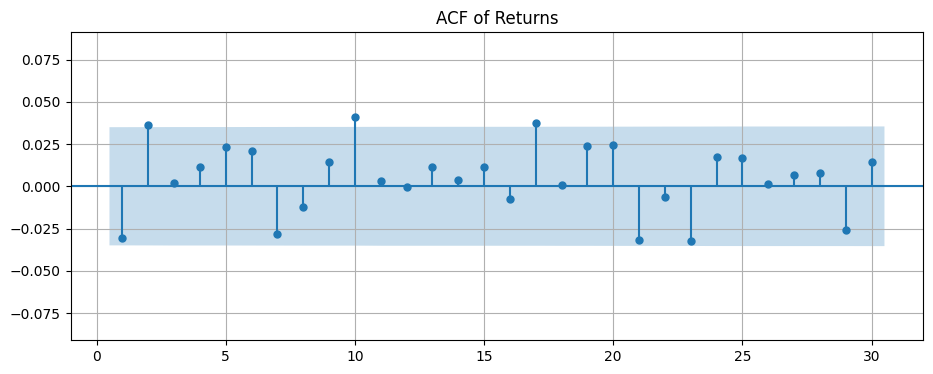

Saved figure → outputs/figures/acf_realised_volatility.png


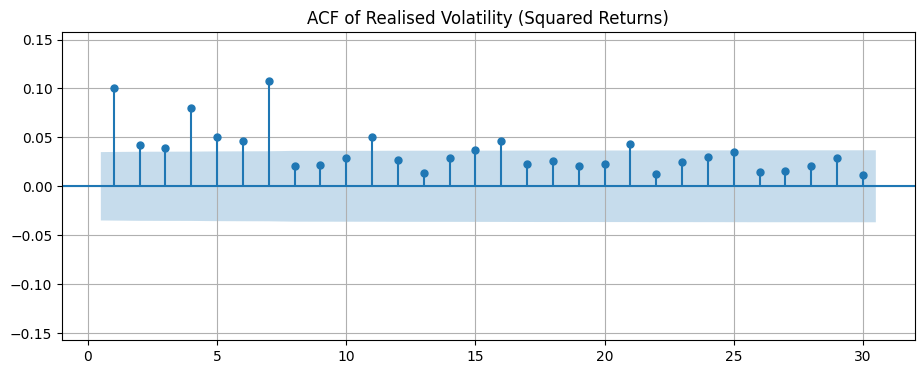

Saved LaTeX table → outputs/tables/ljung_box_dependence.tex
  Label: tab:ljung_box_dependence
Ljung-Box dependence diagnostics:


,Returns,Realised Volatility (Squared Returns)
Lag 10,0.034366,7.190884e-21
Lag 20,0.094799,4.640968e-22
Lag 30,0.098065,8.330886e-22


In [320]:
# -------------------------
# 4.1.3 Dependence and Persistence Diagnostics
# -------------------------

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt
import numpy as np

ACF_LAGS = 30
MARGIN = 0.05  # extra padding


def dynamic_acf_plot(series, filename, title):
    series = series.dropna()

    acf_vals = acf(series, nlags=ACF_LAGS, fft=True)
    max_acf = np.max(np.abs(acf_vals[1:])) if len(acf_vals) > 1 else 0
    bound = max_acf + MARGIN

    fig, ax = plt.subplots()
    plot_acf(series, lags=ACF_LAGS, zero=False, ax=ax)

    ax.set_ylim(-bound, bound)
    ax.set_title(title)

    save_figure_png(filename)
    plt.show()
    plt.close(fig)


# -------------------------
# ACF of Returns
# -------------------------
dynamic_acf_plot(
    df["log_return"],
    "acf_returns.png",
    "ACF of Returns"
)

# -------------------------
# ACF of Realised Volatility
# -------------------------
dynamic_acf_plot(
    df["RV"],
    "acf_realised_volatility.png",
    "ACF of Realised Volatility (Squared Returns)"
)

# -------------------------
# Ljung-Box Tests
# -------------------------
lb_returns = acorr_ljungbox(
    df["log_return"].dropna(),
    lags=[10, 20, 30],
    return_df=True
)

lb_rv = acorr_ljungbox(
    df["RV"].dropna(),
    lags=[10, 20, 30],
    return_df=True
)

lb_table = pd.concat({
    "Returns": lb_returns["lb_pvalue"],
    "Realised Volatility (Squared Returns)": lb_rv["lb_pvalue"]
}, axis=1)

# Make lag labels cleaner
lb_table.index = [f"Lag {i}" for i in lb_table.index]

save_table_latex(
    lb_table,
    "ljung_box_dependence.tex",
    caption="Ljung–Box test p-values for dependence diagnostics of returns and realised volatility proxied by squared returns.",
    label="tab:ljung_box_dependence"
)

print("Ljung-Box dependence diagnostics:")
display(lb_table)

### 4.1.4 Normality and distributional tests
Jarque-Bera test
- statistic
- p-value

In [321]:
# -------------------------
# 4.1.4 Normality and Distributional Tests
# -------------------------

from scipy.stats import jarque_bera

def jarque_bera_test(series: pd.Series) -> pd.Series:
    jb_stat, jb_pvalue = jarque_bera(series.dropna())
    return pd.Series({
        "JB Statistic": jb_stat,
        "p-value": jb_pvalue
    })

jb_414 = pd.concat({
    "Returns": jarque_bera_test(df["log_return"]),
    "Realised Volatility (Squared Returns)": jarque_bera_test(df["RV"])
}, axis=1)

save_table_latex(
    jb_414,
    "jarque_bera_tests.tex",
    caption="Jarque–Bera normality test results for returns and realised volatility proxied by squared returns.",
    label="tab:jarque_bera",
    float_fmt="%.4f"
)

print("Jarque-Bera normality tests:")
display(jb_414)

Saved LaTeX table → outputs/tables/jarque_bera_tests.tex
  Label: tab:jarque_bera
Jarque-Bera normality tests:


,Returns,Realised Volatility (Squared Returns)
JB Statistic,17975.682564,1.564060e+08
p-value,0.000000,0.000000e+00


The Jarque–Bera test strongly rejects the null hypothesis of normality for returns, squared returns, and realised volatility (p < 0.001). The large test statistics reflect substantial skewness and excess kurtosis in the Bitcoin return distribution, consistent with heavy-tailed behaviour commonly observed in cryptocurrency markets. These findings motivate the inclusion of Student-t innovations in the GARCH framework and support the exploration of nonlinear machine learning approaches.

### 4.1.5: Stationarity diagnostics
ADF tests
KPSS tests for robustness

In [322]:
# -------------------------
# 4.1.5 ADF Stationarity Tests
# -------------------------

from statsmodels.tsa.stattools import adfuller

def adf_test(series: pd.Series, maxlag: int = None) -> pd.Series:
    result = adfuller(series.dropna(), maxlag=maxlag, autolag="AIC")

    return pd.Series({
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Used Lags": result[2],
        "Observations": result[3]
    })

adf_415 = pd.concat({
    "Returns": adf_test(df["log_return"]),
    "Realised Volatility (Squared Returns)": adf_test(df["RV"]),
    "Sentiment": adf_test(df["Search_Interest"])
}, axis=1)

save_table_latex(
    adf_415,
    "adf_stationarity_tests.tex",
    caption="ADF unit root test results for returns, realised volatility proxied by squared returns, and sentiment.",
    label="tab:adf",
    float_fmt="%.4f"
)

print("ADF stationarity tests:")
display(adf_415)

Saved LaTeX table → outputs/tables/adf_stationarity_tests.tex
  Label: tab:adf
ADF stationarity tests:


,Returns,Realised Volatility (Squared Returns),Sentiment
ADF Statistic,-38.812076,-1.674082e+01,-4.638314
p-value,0.000000,1.358719e-29,0.000110
Used Lags,1.000000,6.000000e+00,29.000000
Observations,3140.000000,3.135000e+03,3112.000000


The Augmented Dickey–Fuller tests reject the null hypothesis of a unit root for returns, squared returns, realised volatility, and sentiment (p < 0.01 in all cases). These findings indicate that all variables are stationary in levels, supporting the validity of ARCH/GARCH modelling and direct inclusion of sentiment measures without further differencing.

### 4.1.6 KPSS Stationarity Test

In [323]:
# -------------------------
# 4.1.6 KPSS Stationarity Tests
# -------------------------

from statsmodels.tsa.stattools import kpss

def kpss_test(series: pd.Series, regression: str = "c") -> pd.Series:
    stat, p_value, lags, _ = kpss(
        series.dropna(),
        regression=regression,
        nlags="auto"
    )

    return pd.Series({
        "KPSS Statistic": stat,
        "p-value": p_value,
        "Used Lags": lags
    })

kpss_416 = pd.concat({
    "Returns": kpss_test(df["log_return"]),
    "Realised Volatility (Squared Returns)": kpss_test(df["RV"]),
    "Sentiment": kpss_test(df["Search_Interest"])
}, axis=1)

save_table_latex(
    kpss_416,
    "kpss_stationarity_tests.tex",
    caption="KPSS stationarity test results for returns, realised volatility proxied by squared returns, and sentiment.",
    label="tab:kpss",
    float_fmt="%.4f"
)

print("KPSS stationarity tests:")
display(kpss_416)

Saved LaTeX table → outputs/tables/kpss_stationarity_tests.tex
  Label: tab:kpss
KPSS stationarity tests:


,Returns,Realised Volatility (Squared Returns),Sentiment
KPSS Statistic,0.142971,2.151845,1.282713
p-value,0.100000,0.010000,0.010000
Used Lags,8.000000,17.000000,31.000000


While the ADF tests reject the presence of a unit root in all variables, the KPSS test rejects stationarity for squared returns, realised volatility, and sentiment. This apparent discrepancy reflects the high persistence typical of volatility and attention measures rather than genuine non-stationarity. In line with standard financial time-series evidence, the variables are treated as stationary but highly persistent processes suitable for ARCH/GARCH and machine learning modelling.

### 4.1.7 Correlation analysis
#### a: Correlation matrix

In [324]:
# -------------------------
# 4.1.7 Correlation Analysis
# -------------------------

corr_vars = [
    "log_return",
    "abs_return",
    "RV",
    "Search_Interest"
]

# Rename for cleaner LaTeX output
corr_df = df[corr_vars].copy()
corr_df.columns = [
    "Returns",
    "Absolute Returns",
    "Realised Volatility (Squared Returns)",
    "Sentiment"
]

# -------------------------
# Pearson Correlation
# -------------------------
corr_417 = corr_df.corr().round(4)

save_table_latex(
    corr_417,
    "correlation_matrix.tex",
    caption="Pearson correlation matrix for returns, absolute returns, realised volatility proxied by squared returns, and sentiment.",
    label="tab:correlation",
    float_fmt="%.4f"
)

print("Pearson correlation matrix:")
display(corr_417)


# -------------------------
# Spearman Correlation
# -------------------------
corr_417_spearman = corr_df.corr(method="spearman").round(4)

save_table_latex(
    corr_417_spearman,
    "correlation_matrix_spearman.tex",
    caption="Spearman rank correlation matrix for returns, absolute returns, realised volatility proxied by squared returns, and sentiment.",
    label="tab:correlation_spearman",
    float_fmt="%.4f"
)

print("Spearman correlation matrix:")
display(corr_417_spearman)

Saved LaTeX table → outputs/tables/correlation_matrix.tex
  Label: tab:correlation
Pearson correlation matrix:


,Returns,Absolute Returns,Realised Volatility (Squared Returns),Sentiment
Returns,1.0000,-0.0326,-0.1569,-0.0212
Absolute Returns,-0.0326,1.0000,0.7690,0.1514
Realised Volatility (Squared Returns),-0.1569,0.7690,1.0000,0.1104
Sentiment,-0.0212,0.1514,0.1104,1.0000


Saved LaTeX table → outputs/tables/correlation_matrix_spearman.tex
  Label: tab:correlation_spearman
Spearman correlation matrix:


,Returns,Absolute Returns,Realised Volatility (Squared Returns),Sentiment
Returns,1.0000,0.0754,0.0754,-0.0275
Absolute Returns,0.0754,1.0000,1.0000,0.0943
Realised Volatility (Squared Returns),0.0754,1.0000,1.0000,0.0943
Sentiment,-0.0275,0.0943,0.0943,1.0000


The correlation analysis reveals negligible linear association between returns and other variables, consistent with market efficiency in mean dynamics. Volatility measures exhibit strong internal dependence, reflecting volatility clustering. Sentiment displays weak but positive correlation with volatility measures, suggesting that its predictive contribution may operate through nonlinear or interaction effects rather than simple linear channels, thereby motivating the use of machine learning techniques.

## 4.2 Model estimation results
### 4.2.0 Estimation and training setup

In [326]:
# -------------------------
# 4.2.0 Estimation Sample Definition
# -------------------------

# Ensure chronological order
df = df.sort_index().copy()

# Total sample size
T = len(df)
split_idx = int(np.floor((1 - TEST_SIZE) * T))

# Estimation and OOS samples
df_est = df.iloc[:split_idx].copy()
df_oos = df.iloc[split_idx:].copy()

# -------------------------
# Sanity checks
# -------------------------
if len(df_oos) == 0:
    raise ValueError("Out-of-sample set is empty.")

if len(df_est) == 0:
    raise ValueError("Estimation sample is empty.")

# Check chronological separation
if df_est.index.max() >= df_oos.index.min():
    print("Note: estimation sample ends immediately before OOS sample begins.")
    print(f"Last estimation date: {df_est.index.max().date()}")
    print(f"First OOS date:       {df_oos.index.min().date()}")

# Optional rolling-window feasibility check
if "TRAIN_ROLLING_WINDOW" in globals():
    if len(df_est) <= TRAIN_ROLLING_WINDOW:
        raise ValueError("Estimation sample too small relative to rolling window size.")

# -------------------------
# Summary output
# -------------------------
print(f"Total observations:      {T}")
print(f"In-sample (estimation):  {len(df_est)}")
print(f"Out-of-sample:           {len(df_oos)}")
print(f"In-sample start/end:     {df_est.index.min().date()} → {df_est.index.max().date()}")
print(f"Out-of-sample start/end: {df_oos.index.min().date()} → {df_oos.index.max().date()}")

print("\nFirst 5 rows of estimation sample:")
display(df_est.head())

print("\nFirst 5 rows of OOS sample:")
display(df_oos.head())

Total observations:      3142
In-sample (estimation):  2513
Out-of-sample:           629
In-sample start/end:     2017-01-02 → 2023-11-19
Out-of-sample start/end: 2023-11-20 → 2025-08-09

First 5 rows of estimation sample:


,Open,Close,Volume,Search_Interest,log_return,sq_return,abs_return,RV,log_volume,Search_Interest_lag
Date,,,,,,,,,,
2017-01-02,998.617004,1021.750000,222184992.0,27,2.319324,5.379262,2.319324,5.379262,19.219021,14.0
2017-01-03,1021.599976,1043.839966,185168000.0,25,2.138934,4.575041,2.138934,4.575041,19.036774,27.0
2017-01-04,1044.400024,1154.729980,344945984.0,28,10.096034,101.929912,10.096034,101.929912,19.658898,25.0
2017-01-05,1156.729980,1013.380005,510199008.0,35,-13.057525,170.498959,13.057525,170.498959,20.050311,28.0
2017-01-06,1014.239990,902.200989,351876000.0,29,-11.620924,135.045878,11.620924,135.045878,19.678789,35.0



First 5 rows of OOS sample:


,Open,Close,Volume,Search_Interest,log_return,sq_return,abs_return,RV,log_volume,Search_Interest_lag
Date,,,,,,,,,,
2023-11-20,37374.07422,37476.95703,2.088821e+10,54,0.241533,0.058338,0.241533,0.058338,23.762451,46.0
2023-11-21,37469.16016,35813.81250,2.517216e+10,53,-4.539262,20.604901,4.539262,20.604901,23.949005,54.0
2023-11-22,35756.55469,37432.33984,2.439725e+10,53,4.420139,19.537628,4.420139,19.537628,23.917736,53.0
2023-11-23,37420.43359,37289.62109,1.421495e+10,49,-0.382000,0.145924,0.382000,0.145924,23.377560,53.0
2023-11-24,37296.31641,37720.28125,2.292296e+10,52,1.148288,1.318566,1.148288,1.318566,23.855405,49.0


### 4.2.1 Model specification and estimation setup

In [328]:
# -------------------------
# 4.2.1 Model specifications & estimation setup
# -------------------------

# =====================================================
# Core choices (aligned with Chapter 3 and R estimation)
# =====================================================

RETURN_COL = "log_return"
SENT_COL = "Search_Interest_lag"

# Main volatility target (must match R OOS export)
VOL_COL = "sq_return"   # Squared returns (r_t^2)

# Safety check: never allow accidental change
if VOL_COL != "sq_return":
    raise ValueError("Main evaluation must use squared returns (r_t^2).")

# Additional safety check
if SENT_COL not in df.columns:
    raise ValueError(f"Sentiment column '{SENT_COL}' not found in transformed data.")

# -------------------------
# GARCH family specifications
# -------------------------

GARCH_P, GARCH_Q = 1, 1
INNOVATIONS = ["normal", "t"]

# Benchmark model
BENCHMARK_MODEL = "GARCH_Normal"

# -------------------------
# Random Forest feature sets
# -------------------------

RF_BASE_FEATURES = [
    "log_return",
    "sq_return",
    "abs_return",
    "log_volume",
]

RF_SENT_FEATURES = RF_BASE_FEATURES + [SENT_COL]

# -------------------------
# Reproducibility table
# -------------------------

spec_421 = pd.DataFrame(
    {
        "Setting": [
            "Return variable",
            "Volatility proxy (target)",
            "Sentiment variable",
            "Benchmark model",
            "GARCH order (p,q)",
            "GARCH innovations compared",
            "RF baseline features",
            "RF sentiment-augmented features",
            "In-sample size",
            "Out-of-sample size",
        ],
        "Value": [
            RETURN_COL,
            "Squared returns (r_t^2)",
            SENT_COL,
            BENCHMARK_MODEL,
            f"({GARCH_P},{GARCH_Q})",
            ", ".join(INNOVATIONS),
            ", ".join(RF_BASE_FEATURES),
            ", ".join(RF_SENT_FEATURES),
            str(len(df_est)),
            str(len(df_oos)),
        ],
    }
)

save_table_latex(
    spec_421,
    "model_specifications_setup.tex",
    caption="Model specifications and estimation setup. The primary volatility target is squared returns, consistent with the GARCH-family forecasts generated in R.",
    label="tab:model_spec",
)

print("Model specifications and estimation setup:")
display(spec_421)

Saved LaTeX table → outputs/tables/model_specifications_setup.tex
  Label: tab:model_spec
Model specifications and estimation setup:


,Setting,Value
0,Return variable,log_return
1,Volatility proxy (target),Squared returns (r_t^2)
2,Sentiment variable,Search_Interest_lag
3,Benchmark model,GARCH_Normal
4,"GARCH order (p,q)","(1,1)"
5,GARCH innovations compared,"normal, t"
6,RF baseline features,"log_return, sq_return, abs_return, log_volume"
7,RF sentiment-augmented features,"log_return, sq_return, abs_return, log_volume,..."
8,In-sample size,2513
9,Out-of-sample size,629


### 4.2.2 Baseline econometric volatility models

#### Import ALL GARCH-Family Parameters

In [330]:
# ==========================================================
# 4.2.2 GARCH-Family Parameter Estimates (Imported from R)
# ==========================================================

# -------------------------
# Load parameter estimates from R
# -------------------------
garch_family_params = pd.read_csv(
    GARCH_FAMILY_DIR / "garch_family_params_from_r.csv"
)

# -------------------------
# Basic validation
# -------------------------
required_cols = ["param", "model", "coef", "std_error", "t_value", "p_value"]
missing_cols = [col for col in required_cols if col not in garch_family_params.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in garch_family_params_from_r.csv: {missing_cols}")

# -------------------------
# Rename columns for presentation
# -------------------------
garch_family_params = garch_family_params.rename(columns={
    "coef": "Coef.",
    "std_error": "Std.Err.",
    "t_value": "t-stat",
    "p_value": "p-value"
})

# -------------------------
# Clean parameter names
# -------------------------
name_map = {
    "mu": "mu",
    "omega": "omega",
    "alpha1": "alpha[1]",
    "beta1": "beta[1]",
    "vxreg1": "gamma",
    "shape": "nu",
    "loglik": "Log-Likelihood",
    "AIC": "AIC",
    "BIC": "BIC"
}

garch_family_params["param"] = garch_family_params["param"].replace(name_map)

# -------------------------
# Pivot to wide format
# Columns become: (model, statistic)
# -------------------------
garch_table = garch_family_params.pivot(
    index="param",
    columns="model",
    values=["Coef.", "Std.Err.", "t-stat", "p-value"]
)

garch_table = garch_table.swaplevel(0, 1, axis=1).sort_index(axis=1)

# -------------------------
# Clean parameter labels for LaTeX
# -------------------------
garch_table.index = garch_table.index.astype(str)
garch_table.index = garch_table.index.str.replace("[", "(", regex=False)
garch_table.index = garch_table.index.str.replace("]", ")", regex=False)

# -------------------------
# Model groups
# -------------------------
garch_models = ["GARCH_Normal", "GARCH_Student_t"]
igarch_models = ["IGARCH_Normal", "IGARCH_Student_t"]

# Check that requested models exist
available_models = garch_table.columns.get_level_values(0).unique().tolist()

missing_garch = [m for m in garch_models if m not in available_models]
missing_igarch = [m for m in igarch_models if m not in available_models]

if missing_garch:
    raise ValueError(f"Missing expected baseline GARCH models: {missing_garch}")
if missing_igarch:
    raise ValueError(f"Missing expected baseline IGARCH models: {missing_igarch}")

# -------------------------
# Split baseline tables
# -------------------------
idx = pd.IndexSlice

garch_baseline = garch_table.loc[:, idx[garch_models, :]]
igarch_baseline = garch_table.loc[:, idx[igarch_models, :]]

# -------------------------
# Optional: cleaner column order within each model
# -------------------------
stat_order = ["Coef.", "Std.Err.", "t-stat", "p-value"]

garch_baseline = garch_baseline.reindex(
    columns=pd.MultiIndex.from_product([garch_models, stat_order]),
    fill_value=np.nan
)

igarch_baseline = igarch_baseline.reindex(
    columns=pd.MultiIndex.from_product([igarch_models, stat_order]),
    fill_value=np.nan
)

# -------------------------
# Save tables
# -------------------------
save_table_latex(
    garch_baseline,
    "garch_parameters.tex",
    caption="Parameter estimates for baseline GARCH models imported from the R estimation step.",
    label="tab:garch_params"
)

save_table_latex(
    igarch_baseline,
    "igarch_parameters.tex",
    caption="Parameter estimates for baseline IGARCH models imported from the R estimation step.",
    label="tab:igarch_params"
)

print("Baseline GARCH parameter table:")
display(garch_baseline)

print("\nBaseline IGARCH parameter table:")
display(igarch_baseline)

Saved LaTeX table → outputs/tables/garch_parameters.tex
  Label: tab:garch_params
Saved LaTeX table → outputs/tables/igarch_parameters.tex
  Label: tab:igarch_params
Baseline GARCH parameter table:


GARCH_Normal                                     \
                      Coef.  Std.Err.     t-stat       p-value   
param                                                            
AIC                5.289366       NaN        NaN           NaN   
BIC                5.297071       NaN        NaN           NaN   
Log-Likelihood -8305.593872       NaN        NaN           NaN   
alpha(1)           0.119218  0.014248   8.367111  0.000000e+00   
beta(1)            0.840223  0.016680  50.372171  0.000000e+00   
mu                 0.185834  0.055157   3.369195  7.538803e-04   
nu                      NaN       NaN        NaN           NaN   
omega              0.661183  0.099552   6.641605  3.102851e-11   

               GARCH_Student_t                                     
                         Coef.  Std.Err.     t-stat       p-value  
param                                                              
AIC                   5.065496       NaN        NaN           NaN  
BIC                   5.075128       NaN        NaN           NaN  
Log-Likelihood    -7952.894206       NaN        NaN           NaN  
alpha(1)              0.085734  0.013881   6.176468  6.555163e-10  
beta(1)               0.913266  0.016292  56.057770  0.000000e+00  
mu                    0.121547  0.041067   2.959719  3.079202e-03  
nu                    3.241139  0.183317  17.680511  0.000000e+00  
omega                 0.172727  0.080119   2.155895  3.109185e-02


Baseline IGARCH parameter table:


IGARCH_Normal                                    \
                       Coef.  Std.Err.    t-stat       p-value   
param                                                            
AIC                 5.297503       NaN       NaN           NaN   
BIC                 5.303282       NaN       NaN           NaN   
Log-Likelihood  -8319.377434       NaN       NaN           NaN   
alpha(1)            0.163891  0.016824  9.741473  0.000000e+00   
beta(1)             0.836109       NaN       NaN           NaN   
mu                  0.180225  0.054617  3.299799  9.675409e-04   
nu                       NaN       NaN       NaN           NaN   
omega               0.493541  0.074965  6.583609  4.591616e-11   

               IGARCH_Student_t                                     
                          Coef.  Std.Err.     t-stat       p-value  
param                                                               
AIC                    5.064689       NaN        NaN           NaN  
BIC                    5.072395       NaN        NaN           NaN  
Log-Likelihood     -7952.626915       NaN        NaN           NaN  
alpha(1)               0.085879  0.013235   6.488581  8.664847e-11  
beta(1)                0.914121       NaN        NaN           NaN  
mu                     0.121114  0.040833   2.966079  3.016235e-03  
nu                     3.226959  0.133732  24.130041  0.000000e+00  
omega                  0.167422  0.060145   2.783637  5.375323e-03

### 4.2.3 Import OOS Forecasts

In [331]:
# ==========================================================
# 4.2.3 Import Walk-Forward OOS Forecasts (From R)
# ==========================================================

forecast_file = GARCH_FAMILY_DIR / "garch_family_oos_forecasts_from_r.csv"

if not forecast_file.exists():
    raise FileNotFoundError(
        "Missing OOS forecast file. Run the R GARCH-family script first."
    )

# -------------------------
# Load forecasts
# -------------------------
forecasts_oos = pd.read_csv(forecast_file)

# -------------------------
# Validate required columns
# -------------------------
required_cols = [
    "Date",
    "Realized_Variance",
    "GARCH_Normal",
    "GARCH_Student_t",
    "GARCHX_Normal",
    "GARCHX_Student_t",
    "IGARCH_Normal",
    "IGARCH_Student_t",
    "IGARCHX_Normal",
    "IGARCHX_Student_t",
]

missing_cols = [col for col in required_cols if col not in forecasts_oos.columns]
if missing_cols:
    raise ValueError(
        f"Missing required columns in garch_family_oos_forecasts_from_r.csv: {missing_cols}"
    )

# -------------------------
# Parse dates
# -------------------------
forecasts_oos["Date"] = pd.to_datetime(forecasts_oos["Date"], errors="coerce")

if forecasts_oos["Date"].isna().any():
    bad_rows = forecasts_oos.loc[forecasts_oos["Date"].isna()].head(10)
    raise ValueError(f"Date parsing failed in forecast file. Problem rows:\n{bad_rows}")

forecasts_oos = forecasts_oos.set_index("Date").sort_index()

# -------------------------
# Ensure numeric forecasts
# -------------------------
for col in forecasts_oos.columns:
    forecasts_oos[col] = pd.to_numeric(forecasts_oos[col], errors="coerce")

# -------------------------
# Basic checks
# -------------------------
if forecasts_oos.index.has_duplicates:
    raise ValueError("Duplicate dates detected in R OOS forecast file.")

if forecasts_oos.index.hasnans:
    raise ValueError("NaT values detected in R OOS forecast index.")

if forecasts_oos.isna().any().any():
    na_counts = forecasts_oos.isna().sum()
    print("Warning: Missing values detected in OOS forecasts.")
    display(na_counts[na_counts > 0])

print("✓ OOS forecasts loaded.")
print("Date range:", forecasts_oos.index.min().date(), "→", forecasts_oos.index.max().date())
print("Rows:", len(forecasts_oos))

print("\nForecast models:")
print(list(forecasts_oos.columns))

# -------------------------
# Alignment check against Python OOS sample
# -------------------------
common_dates = forecasts_oos.index.intersection(df_oos.index)

print("\nAlignment check against df_oos:")
print("R forecast rows:", len(forecasts_oos))
print("Python OOS rows:", len(df_oos))
print("Common dates:", len(common_dates))
print("Only in R:", len(forecasts_oos.index.difference(df_oos.index)))
print("Only in Python:", len(df_oos.index.difference(forecasts_oos.index)))

if len(common_dates) != len(forecasts_oos) or len(common_dates) != len(df_oos):
    raise ValueError(
        "R OOS forecasts and Python df_oos are not perfectly aligned. "
        "Check the transformation and sample split steps."
    )

# -------------------------
# Final aligned forecast object
# -------------------------
garch_fc_r = forecasts_oos.copy()

print("\n✓ R OOS forecasts are fully aligned with Python df_oos.")
display(garch_fc_r.head())

✓ OOS forecasts loaded.
Date range: 2023-11-20 → 2025-08-09
Rows: 629

Forecast models:
['Realized_Variance', 'GARCH_Normal', 'GARCH_Student_t', 'GARCHX_Normal', 'GARCHX_Student_t', 'IGARCH_Normal', 'IGARCH_Student_t', 'IGARCHX_Normal', 'IGARCHX_Student_t']

Alignment check against df_oos:
R forecast rows: 629
Python OOS rows: 629
Common dates: 629
Only in R: 0
Only in Python: 0

✓ R OOS forecasts are fully aligned with Python df_oos.


,Realized_Variance,GARCH_Normal,GARCH_Student_t,GARCHX_Normal,GARCHX_Student_t,IGARCH_Normal,IGARCH_Student_t,IGARCHX_Normal,IGARCHX_Student_t
Date,,,,,,,,,
2023-11-20,0.058338,4.906703,9.431624,4.906699,12.676059,4.607245,9.440372,4.607249,9.440748
2023-11-21,20.604901,4.778366,8.663161,4.778105,11.257581,4.547033,8.672472,4.547026,8.672279
2023-11-22,19.537628,5.137439,9.848868,5.137433,12.395659,4.763051,9.859070,4.763053,9.858404
2023-11-23,0.145924,5.496478,11.363585,5.496540,15.374996,4.949441,11.377700,4.949450,11.377577
2023-11-24,1.318566,5.344907,10.304499,5.344908,13.167455,4.887473,10.321957,4.887473,10.321708


### 4.2.4 Sentiment-augmented econometric models

In [332]:
# ==========================================================
# 4.2.4 GARCH-X & IGARCH-X — Imported from R
# ==========================================================

# ----------------------------------------------------------
# (A) Import sentiment-augmented parameters
# ----------------------------------------------------------

garchx_file = GARCH_FAMILY_DIR / "garchx_params_from_r.csv"

if not garchx_file.exists():
    raise FileNotFoundError(
        "Missing sentiment-augmented parameter file: garchx_params_from_r.csv"
    )

garchx_r = pd.read_csv(garchx_file)

required_cols = ["param", "model", "coef", "std_error", "t_value", "p_value"]
missing_cols = [col for col in required_cols if col not in garchx_r.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in garchx_params_from_r.csv: {missing_cols}")

garchx_r = garchx_r.rename(columns={
    "coef": "Coef.",
    "std_error": "Std.Err.",
    "t_value": "t-stat",
    "p_value": "p-value"
})

# ----------------------------------------------------------
# (B) Clean rugarch parameter names
# ----------------------------------------------------------

name_map = {
    "mu": "mu",
    "omega": "omega",
    "alpha1": "alpha[1]",
    "beta1": "beta[1]",
    "shape": "nu",
    "vxreg1": SENT_COL,
    "loglik": "Log-Likelihood",
    "AIC": "AIC",
    "BIC": "BIC"
}

garchx_r["param"] = garchx_r["param"].replace(name_map)

# ----------------------------------------------------------
# (C) Pivot to presentation format
# ----------------------------------------------------------

garchx_table = garchx_r.pivot(
    index="param",
    columns="model",
    values=["Coef.", "Std.Err.", "t-stat", "p-value"]
)

garchx_table = garchx_table.swaplevel(0, 1, axis=1).sort_index(axis=1)

# ----------------------------------------------------------
# (D) Order parameters
# ----------------------------------------------------------

preferred_order = [
    "mu",
    SENT_COL,
    "omega",
    "alpha[1]",
    "beta[1]",
    "nu",
    "Log-Likelihood",
    "AIC",
    "BIC"
]

garchx_table = garchx_table.reindex(
    [r for r in preferred_order if r in garchx_table.index]
    + [r for r in garchx_table.index if r not in preferred_order]
)

garchx_table.index = garchx_table.index.astype(str)
garchx_table.index = garchx_table.index.str.replace("[", "(", regex=False)
garchx_table.index = garchx_table.index.str.replace("]", ")", regex=False)

# ----------------------------------------------------------
# (E) Split GARCH-X and IGARCH-X
# ----------------------------------------------------------

garchx_models = ["GARCHX_Normal", "GARCHX_Student_t"]
igarchx_models = ["IGARCHX_Normal", "IGARCHX_Student_t"]

available_models = garchx_table.columns.get_level_values(0).unique().tolist()

missing_garchx = [m for m in garchx_models if m not in available_models]
missing_igarchx = [m for m in igarchx_models if m not in available_models]

if missing_garchx:
    raise ValueError(f"Missing expected GARCH-X models: {missing_garchx}")
if missing_igarchx:
    raise ValueError(f"Missing expected IGARCH-X models: {missing_igarchx}")

idx = pd.IndexSlice

garchx_params = garchx_table.loc[:, idx[garchx_models, :]]
igarchx_params = garchx_table.loc[:, idx[igarchx_models, :]]

# Optional: enforce statistic order
stat_order = ["Coef.", "Std.Err.", "t-stat", "p-value"]

garchx_params = garchx_params.reindex(
    columns=pd.MultiIndex.from_product([garchx_models, stat_order]),
    fill_value=np.nan
)

igarchx_params = igarchx_params.reindex(
    columns=pd.MultiIndex.from_product([igarchx_models, stat_order]),
    fill_value=np.nan
)

# ----------------------------------------------------------
# (F) Save tables
# ----------------------------------------------------------

save_table_latex(
    garchx_params,
    "garchx_parameters.tex",
    caption="Parameter estimates for sentiment-augmented GARCH-X models imported from the R estimation step.",
    label="tab:garchx_params",
    float_fmt="%.4f"
)

save_table_latex(
    igarchx_params,
    "igarchx_parameters.tex",
    caption="Parameter estimates for sentiment-augmented IGARCH-X models imported from the R estimation step.",
    label="tab:igarchx_params",
    float_fmt="%.4f"
)

print("GARCH-X parameter table:")
display(garchx_params)

print("\nIGARCH-X parameter table:")
display(igarchx_params)

Saved LaTeX table → outputs/tables/garchx_parameters.tex
  Label: tab:garchx_params
Saved LaTeX table → outputs/tables/igarchx_parameters.tex
  Label: tab:igarchx_params
GARCH-X parameter table:


GARCHX_Normal                                        \
                            Coef.  Std.Err.        t-stat       p-value   
param                                                                     
mu                   1.859022e-01  0.055287  3.362469e+00  7.724866e-04   
Search_Interest_lag  6.469654e-09  0.061585  1.050519e-07  9.999999e-01   
omega                6.621484e-01  0.135310  4.893567e+00  9.902463e-07   
alpha(1)             1.193453e-01  0.016498  7.233809e+00  4.696243e-13   
beta(1)              8.399767e-01  0.021181  3.965760e+01  0.000000e+00   
nu                            NaN       NaN           NaN           NaN   
Log-Likelihood      -8.302869e+03       NaN           NaN           NaN   
AIC                  5.289951e+00       NaN           NaN           NaN   
BIC                  5.299586e+00       NaN           NaN           NaN   

                    GARCHX_Student_t                                    
                               Coef.  Std.Err.        t-stat   p-value  
param                                                                   
mu                      1.136008e-01  0.040302  2.818771e+00  0.004821  
Search_Interest_lag     7.619781e-09  0.037705  2.020895e-07  1.000000  
omega                   1.156335e-01  0.067145  1.722137e+00  0.085045  
alpha(1)                1.064377e-01  0.022501  4.730321e+00  0.000002  
beta(1)                 9.188565e-01  0.014302  6.424627e+01  0.000000  
nu                      2.879154e+00  0.183775  1.566672e+01  0.000000  
Log-Likelihood         -7.947441e+03       NaN           NaN       NaN  
AIC                     5.064273e+00       NaN           NaN       NaN  
BIC                     5.075834e+00       NaN           NaN       NaN


IGARCH-X parameter table:


IGARCHX_Normal                                        \
                             Coef.  Std.Err.        t-stat       p-value   
param                                                                      
mu                    1.803958e-01  0.054618  3.302868e+00  9.570152e-04   
Search_Interest_lag   6.663145e-10  0.058570  1.137632e-08  1.000000e+00   
omega                 4.940191e-01  0.105716  4.673062e+00  2.967428e-06   
alpha(1)              1.641297e-01  0.021564  7.611438e+00  2.708944e-14   
beta(1)               8.358703e-01       NaN           NaN           NaN   
nu                             NaN       NaN           NaN           NaN   
Log-Likelihood       -8.316692e+03       NaN           NaN           NaN   
AIC                   5.298116e+00       NaN           NaN           NaN   
BIC                   5.305824e+00       NaN           NaN           NaN   

                    IGARCHX_Student_t                                        
                                Coef.  Std.Err.        t-stat       p-value  
param                                                                        
mu                       1.204505e-01  0.041143  2.927598e+00  3.415910e-03  
Search_Interest_lag      9.923149e-09  0.034819  2.849938e-07  9.999998e-01  
omega                    1.677608e-01  0.063536  2.640385e+00  8.281189e-03  
alpha(1)                 8.601444e-02  0.013885  6.194558e+00  5.844885e-10  
beta(1)                  9.139856e-01       NaN           NaN           NaN  
nu                       3.226868e+00  0.135507  2.381322e+01  0.000000e+00  
Log-Likelihood          -7.950203e+03       NaN           NaN           NaN  
AIC                      5.065395e+00       NaN           NaN           NaN  
BIC                      5.075029e+00       NaN           NaN           NaN

### 4.2.4 Econometric model diagnostics

Helper functions

In [333]:
# ==========================================================
# 4.2.5 Econometric Model Diagnostics (Imported from R)
# ==========================================================

# ----------------------------------------------------------
# (A) Import baseline diagnostics
# ----------------------------------------------------------

baseline_diag_file = GARCH_FAMILY_DIR / "garch_family_baseline_diagnostics_from_r.csv"
sentiment_diag_file = GARCH_FAMILY_DIR / "garch_family_sentiment_diagnostics_from_r.csv"

if not baseline_diag_file.exists():
    raise FileNotFoundError(
        "Missing baseline diagnostics file: garch_family_baseline_diagnostics_from_r.csv"
    )

if not sentiment_diag_file.exists():
    raise FileNotFoundError(
        "Missing sentiment diagnostics file: garch_family_sentiment_diagnostics_from_r.csv"
    )

diag_baseline = pd.read_csv(baseline_diag_file)
diag_sentiment = pd.read_csv(sentiment_diag_file)

# ----------------------------------------------------------
# (B) Basic validation
# ----------------------------------------------------------

expected_diag_cols = [
    "lag",
    "lb_stat_resid",
    "lb_pvalue_resid",
    "lb_stat_sqresid",
    "lb_pvalue_sqresid",
    "Model"
]

missing_baseline = [c for c in expected_diag_cols if c not in diag_baseline.columns]
missing_sentiment = [c for c in expected_diag_cols if c not in diag_sentiment.columns]

if missing_baseline:
    raise ValueError(f"Baseline diagnostics file is missing columns: {missing_baseline}")

if missing_sentiment:
    raise ValueError(f"Sentiment diagnostics file is missing columns: {missing_sentiment}")

# ----------------------------------------------------------
# (C) Clean column names for presentation
# ----------------------------------------------------------

diag_baseline = diag_baseline.rename(columns={
    "lag": "Lag",
    "lb_stat_resid": "LB Stat (Resid)",
    "lb_pvalue_resid": "p-value (Resid)",
    "lb_stat_sqresid": "LB Stat (Sq. Resid)",
    "lb_pvalue_sqresid": "p-value (Sq. Resid)"
})

diag_sentiment = diag_sentiment.rename(columns={
    "lag": "Lag",
    "lb_stat_resid": "LB Stat (Resid)",
    "lb_pvalue_resid": "p-value (Resid)",
    "lb_stat_sqresid": "LB Stat (Sq. Resid)",
    "lb_pvalue_sqresid": "p-value (Sq. Resid)"
})

diag_baseline = sanitize_dataframe_columns(diag_baseline)
diag_sentiment = sanitize_dataframe_columns(diag_sentiment)

# ----------------------------------------------------------
# (D) Save baseline diagnostics table
# ----------------------------------------------------------

save_table_latex(
    diag_baseline,
    "garch_baseline_diagnostics.tex",
    caption="Ljung--Box diagnostics for baseline GARCH-family models imported from the R estimation step.",
    label="tab:garch_baseline_diagnostics",
    float_fmt="%.4f"
)

# ----------------------------------------------------------
# (E) Save sentiment diagnostics table
# ----------------------------------------------------------

save_table_latex(
    diag_sentiment,
    "garch_sentiment_diagnostics.tex",
    caption="Ljung--Box diagnostics for sentiment-augmented GARCH-family models imported from the R estimation step.",
    label="tab:garch_sentiment_diagnostics",
    float_fmt="%.4f"
)

print("Baseline diagnostics:")
display(diag_baseline)

print("\nSentiment diagnostics:")
display(diag_sentiment)

print("\nDiagnostics tables saved successfully.")

Saved LaTeX table → outputs/tables/garch_baseline_diagnostics.tex
  Label: tab:garch_baseline_diagnostics
Saved LaTeX table → outputs/tables/garch_sentiment_diagnostics.tex
  Label: tab:garch_sentiment_diagnostics
Baseline diagnostics:


,Lag,LB Stat (Resid),p-value (Resid),LB Stat (Sq. Resid),p-value (Sq. Resid),Model
0,10,16.347682,0.012005,6.142908,0.407374,GARCH_Normal
1,20,22.752715,0.120507,8.803462,0.921286,GARCH_Normal
2,10,17.481694,0.003671,5.492643,0.358753,GARCH_Student_t
3,20,24.665156,0.054625,10.256173,0.803324,GARCH_Student_t
4,10,17.401086,0.007917,6.973597,0.323296,IGARCH_Normal
5,20,24.329096,0.082559,11.174399,0.798595,IGARCH_Normal
6,10,17.521508,0.003610,5.485616,0.359526,IGARCH_Student_t
7,20,24.724087,0.053774,10.272086,0.802285,IGARCH_Student_t



Sentiment diagnostics:


,Lag,LB Stat (Resid),p-value (Resid),LB Stat (Sq. Resid),p-value (Sq. Resid),Model
0,10,16.405473,0.005777,6.120193,0.294699,GARCHX_Normal
1,20,22.766135,0.089233,8.781867,0.888644,GARCHX_Normal
2,10,18.492466,0.000988,5.282077,0.259559,GARCHX_Student_t
3,20,25.926523,0.026449,10.488733,0.725650,GARCHX_Student_t
4,10,17.447251,0.003725,6.954928,0.224014,IGARCHX_Normal
5,20,24.334162,0.059632,11.157871,0.741325,IGARCHX_Normal
6,10,17.597163,0.001479,5.462158,0.243076,IGARCHX_Student_t
7,20,24.761936,0.036992,10.253968,0.743390,IGARCHX_Student_t



Diagnostics tables saved successfully.


Ljung–Box diagnostics indicate that all GARCH-family specifications successfully eliminate remaining ARCH effects, as the null hypothesis of no serial correlation in squared standardized residuals cannot be rejected at conventional significance levels. This confirms that the conditional variance dynamics are adequately captured by both GARCH and IGARCH structures. However, residual autocorrelation remains significant at shorter lags (particularly at lag 10), suggesting mild mean misspecification under the ARMA(0,0) assumption. Importantly, the inclusion of sentiment in the variance equation does not materially alter the adequacy of the volatility specification, indicating that sentiment augmentation preserves model stability while enriching the conditional variance dynamics.

Ljung–Box tests on squared standardized residuals fail to reject the null hypothesis of no remaining autocorrelation at conventional significance levels across all baseline and sentiment-augmented specifications. This indicates that the GARCH-family models adequately capture conditional heteroskedasticity and volatility clustering. While some residual serial correlation persists at shorter lags in standardized residuals—likely reflecting the simple ARMA(0,0) mean specification—this does not undermine the validity of the variance equation. Overall, the diagnostic results support the statistical adequacy of the estimated models.

#### Diagnostics for baseline GARCH and GARCH-X

#### ARCH–LM test on standardized residuals

In [334]:
# ==========================================================
# 4.2.6 ARCH-LM Tests (Imported from R)
# ==========================================================

archlm_file = GARCH_FAMILY_DIR / "garch_family_archlm_from_r.csv"

if not archlm_file.exists():
    raise FileNotFoundError(
        "Missing ARCH-LM results file: garch_family_archlm_from_r.csv"
    )

archlm_results = pd.read_csv(archlm_file)

# -------------------------
# Basic validation
# -------------------------
required_cols = ["Model", "Lags", "ARCH_LM_Stat", "P_Value"]
missing_cols = [col for col in required_cols if col not in archlm_results.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in ARCH-LM file: {missing_cols}")

# -------------------------
# Rename columns for presentation
# -------------------------
archlm_results = archlm_results.rename(columns={
    "ARCH_LM_Stat": "ARCH LM Statistic",
    "P_Value": "p-value"
})

save_table_latex(
    archlm_results,
    "garch_arch_lm_tests.tex",
    caption="ARCH-LM tests for remaining conditional heteroskedasticity in GARCH-family residuals imported from the R estimation step.",
    label="tab:arch_lm_tests",
    float_fmt="%.4f"
)

print("ARCH-LM test results:")
display(archlm_results)

Saved LaTeX table → outputs/tables/garch_arch_lm_tests.tex
  Label: tab:arch_lm_tests
ARCH-LM test results:


,Model,Lags,ARCH LM Statistic,p-value
0,GARCH_Normal,10,6.185384,0.799455
1,GARCH_Student_t,10,5.478113,0.857041
2,IGARCH_Normal,10,7.083048,0.717582
3,IGARCH_Student_t,10,5.468607,0.857761
4,GARCHX_Normal,10,6.179074,0.800000
5,GARCHX_Student_t,10,5.239320,0.874628
6,IGARCHX_Normal,10,7.071026,0.718723
7,IGARCHX_Student_t,10,5.462206,0.858245


Engle’s ARCH-LM tests fail to reject the null hypothesis of no remaining ARCH effects across all baseline and sentiment-augmented specifications. This indicates that the GARCH-family models adequately capture conditional heteroskedasticity in Bitcoin returns. The inclusion of sentiment variables does not introduce residual volatility clustering, confirming that the variance equations remain well specified. These results support the econometric validity of subsequent out-of-sample forecast comparisons.

### 4.2.5 Random Forest Model

#### Preparing target and feature matrices

In [335]:
# ==========================================================
# 4.2.7 Random Forest Models
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# ----------------------------------------------------------
# Ensure chronological order
# ----------------------------------------------------------

df = df.sort_index().copy()

# ----------------------------------------------------------
# (A) Feature Engineering
# ----------------------------------------------------------

df_rf = df.copy()

# Target variable (same as GARCH evaluation)
df_rf["target_vol"] = df_rf["sq_return"]

# ARCH-style dynamics
df_rf["lag_sq_return_1"] = df_rf["sq_return"].shift(1)
df_rf["lag_sq_return_5"] = df_rf["sq_return"].shift(5)

df_rf["lag_abs_return_1"] = df_rf["abs_return"].shift(1)
df_rf["lag_return_1"] = df_rf[RETURN_COL].shift(1)

df_rf["lag_log_volume_1"] = df_rf["log_volume"].shift(1)

# Sentiment lags
df_rf["lag_sentiment_1"] = df_rf[SENT_COL].shift(1)
df_rf["lag_sentiment_5"] = df_rf[SENT_COL].shift(5)

# Drop rows created by lags
rf_required_cols = [
    "target_vol",
    "lag_sq_return_1",
    "lag_sq_return_5",
    "lag_abs_return_1",
    "lag_return_1",
    "lag_log_volume_1",
    "lag_sentiment_1",
    "lag_sentiment_5",
]
df_rf = df_rf.dropna(subset=rf_required_cols).copy()

# ----------------------------------------------------------
# (B) Align RF sample to existing econometric split
# ----------------------------------------------------------
# Use the already-defined estimation and OOS periods
# rather than re-splitting df_rf from scratch.

est_end_date = df_est.index.max()
oos_start_date = df_oos.index.min()
oos_end_date = df_oos.index.max()

train = df_rf.loc[df_rf.index <= est_end_date].copy()
test = df_rf.loc[(df_rf.index >= oos_start_date) & (df_rf.index <= oos_end_date)].copy()

if len(train) == 0:
    raise ValueError("RF training sample is empty after alignment.")

if len(test) == 0:
    raise ValueError("RF OOS sample is empty after alignment.")

print("RF aligned training sample:", len(train))
print("RF aligned OOS sample:", len(test))
print("RF train period:", train.index.min().date(), "→", train.index.max().date())
print("RF OOS period:", test.index.min().date(), "→", test.index.max().date())

# ----------------------------------------------------------
# (C) Feature Sets
# ----------------------------------------------------------

RF_BASE_FEATURES = [
    "lag_sq_return_1",
    "lag_sq_return_5",
    "lag_abs_return_1",
    "lag_return_1",
    "lag_log_volume_1"
]

RF_SENT_FEATURES = RF_BASE_FEATURES + [
    "lag_sentiment_1",
    "lag_sentiment_5"
]

# Target
y_train = train["target_vol"]
y_test = test["target_vol"]

# Feature matrices
X_base_train = train[RF_BASE_FEATURES]
X_base_test = test[RF_BASE_FEATURES]

X_sent_train = train[RF_SENT_FEATURES]
X_sent_test = test[RF_SENT_FEATURES]

# ----------------------------------------------------------
# (D) Time-Series Cross-Validation
# ----------------------------------------------------------

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    "n_estimators": [300, 500],
    "max_depth": [4, 6, 8],
    "min_samples_leaf": [3, 5]
}

# ----------------------------------------------------------
# (E) Baseline Random Forest
# ----------------------------------------------------------

rf_base_cv = GridSearchCV(
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

rf_base_cv.fit(X_base_train, y_train)

rf_base = rf_base_cv.best_estimator_
rf_base_oos = rf_base.predict(X_base_test)

# ----------------------------------------------------------
# (F) Random Forest + Sentiment
# ----------------------------------------------------------

rf_sent_cv = GridSearchCV(
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

rf_sent_cv.fit(X_sent_train, y_train)

rf_sent = rf_sent_cv.best_estimator_
rf_sent_oos = rf_sent.predict(X_sent_test)

# ----------------------------------------------------------
# (G) Store Out-of-Sample Forecasts
# ----------------------------------------------------------

rf_oos_forecasts = pd.DataFrame({
    "Realized": y_test.values,
    "RF_Baseline": rf_base_oos,
    "RF_Sentiment": rf_sent_oos
}, index=test.index)

# ----------------------------------------------------------
# (H) Check alignment against econometric OOS dates
# ----------------------------------------------------------

common_dates = rf_oos_forecasts.index.intersection(df_oos.index)

print("\nRF alignment check against df_oos:")
print("RF OOS rows:", len(rf_oos_forecasts))
print("Python OOS rows:", len(df_oos))
print("Common dates:", len(common_dates))
print("Only in RF:", len(rf_oos_forecasts.index.difference(df_oos.index)))
print("Only in Python OOS:", len(df_oos.index.difference(rf_oos_forecasts.index)))

print("\nRF forecasts generated.")
display(rf_oos_forecasts.head())

RF aligned training sample: 2508
RF aligned OOS sample: 629
RF train period: 2017-01-07 → 2023-11-19
RF OOS period: 2023-11-20 → 2025-08-09


/Users/eokinyo/Library/Python/3.14/lib/python/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/eokinyo/Library/Python/3.14/lib/python/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/eokinyo/Library/Python/3.14/lib/python/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/eokinyo/Library/Python/3.14/lib/python/sit


RF alignment check against df_oos:
RF OOS rows: 629
Python OOS rows: 629
Common dates: 629
Only in RF: 0
Only in Python OOS: 0

RF forecasts generated.


,Realized,RF_Baseline,RF_Sentiment
Date,,,
2023-11-20,0.058338,23.066487,19.755035
2023-11-21,20.604901,11.201328,11.092566
2023-11-22,19.537628,19.051721,17.855063
2023-11-23,0.145924,11.182912,11.296898
2023-11-24,1.318566,10.179523,10.633016


## 4.3 Forecasting performance

#### 4.3.0 Forecasting Setup and Evaluation Design

In [337]:
# ==========================================================
# 4.3.0 Forecast Evaluation Framework
# ==========================================================

import numpy as np
import pandas as pd

# ----------------------------------------------------------
# Forecast Target (consistent with GARCH & RF)
# ----------------------------------------------------------
# Realised volatility proxy:
# RV_t = r_t^2 (squared returns)
# This follows the definition in Chapter 3 methodology.
# ----------------------------------------------------------

FORECAST_TARGET = "sq_return"

# Ensure chronological order
df_oos = df_oos.sort_index().copy()
oos_index = df_oos.index

print(f"Out-of-sample period: {oos_index.min().date()} → {oos_index.max().date()}")
print(f"Number of forecasts:  {len(oos_index)}")

# ----------------------------------------------------------
# Realised volatility proxy
# ----------------------------------------------------------

y_realized_oos = df_oos[FORECAST_TARGET].to_numpy()

if len(y_realized_oos) != len(oos_index):
    raise ValueError("Mismatch between OOS index and realized series.")

# ----------------------------------------------------------
# Loss Functions
# ----------------------------------------------------------

def qlike_loss(realized, forecast, eps=1e-10):
    """
    QLIKE loss under Patton (2011).
    Lower values indicate better forecast performance.
    """
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)

    forecast = np.maximum(forecast, eps)
    realized = np.maximum(realized, eps)

    return (realized / forecast) - np.log(realized / forecast) - 1


def mse_loss(realized, forecast):
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    return (realized - forecast) ** 2


def mae_loss(realized, forecast):
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    return np.abs(realized - forecast)


def evaluate_forecast(realized, forecast):
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)

    if len(realized) != len(forecast):
        raise ValueError("Realized and forecast arrays must have the same length.")

    return pd.Series({
        "QLIKE": np.mean(qlike_loss(realized, forecast)),
        "MSE": np.mean(mse_loss(realized, forecast)),
        "RMSE": np.sqrt(np.mean(mse_loss(realized, forecast))),
        "MAE": np.mean(mae_loss(realized, forecast))
    })

# Containers for later sections
forecast_dict = {}
loss_dict = {}

print("Forecast evaluation framework initialized successfully.")

Out-of-sample period: 2023-11-20 → 2025-08-09
Number of forecasts:  629
Forecast evaluation framework initialized successfully.


### 4.3.1 Econometric models forecasts

In [339]:
# ==========================================================
# 4.3.1 Econometric Model Forecasts (Imported from R)
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# (A) Use already imported and validated R OOS forecasts
# ----------------------------------------------------------

garch_fc_r = forecasts_oos.copy()

# ----------------------------------------------------------
# (B) Final safety checks
# ----------------------------------------------------------

if not garch_fc_r.index.equals(df_oos.index):
    raise ValueError(
        "Econometric forecasts are not aligned with df_oos. "
        "Recheck Section 4.2.3."
    )

missing_counts = garch_fc_r.isna().sum()

print("Missing values in imported econometric forecasts:\n")
print(missing_counts)

if missing_counts.sum() > 0:
    raise ValueError(
        "Missing values detected in imported econometric forecasts. "
        "These should have been resolved before evaluation."
    )

# ----------------------------------------------------------
# (C) Store in Forecast Dictionary
# ----------------------------------------------------------

forecast_dict["GARCH-Normal (R)"] = garch_fc_r["GARCH_Normal"].to_numpy()
forecast_dict["GARCH-Student-t (R)"] = garch_fc_r["GARCH_Student_t"].to_numpy()
forecast_dict["GARCH-X Normal (R)"] = garch_fc_r["GARCHX_Normal"].to_numpy()
forecast_dict["GARCH-X Student-t (R)"] = garch_fc_r["GARCHX_Student_t"].to_numpy()

forecast_dict["IGARCH-Normal (R)"] = garch_fc_r["IGARCH_Normal"].to_numpy()
forecast_dict["IGARCH-Student-t (R)"] = garch_fc_r["IGARCH_Student_t"].to_numpy()
forecast_dict["IGARCH-X Normal (R)"] = garch_fc_r["IGARCHX_Normal"].to_numpy()
forecast_dict["IGARCH-X Student-t (R)"] = garch_fc_r["IGARCHX_Student_t"].to_numpy()

print("\nEconometric forecasts successfully imported and aligned.")

display(pd.DataFrame(forecast_dict, index=df_oos.index).head())

Missing values in imported econometric forecasts:

Realized_Variance    0
GARCH_Normal         0
GARCH_Student_t      0
GARCHX_Normal        0
GARCHX_Student_t     0
IGARCH_Normal        0
IGARCH_Student_t     0
IGARCHX_Normal       0
IGARCHX_Student_t    0
dtype: int64

Econometric forecasts successfully imported and aligned.


,GARCH-Normal (R),GARCH-Student-t (R),GARCH-X Normal (R),GARCH-X Student-t (R),IGARCH-Normal (R),IGARCH-Student-t (R),IGARCH-X Normal (R),IGARCH-X Student-t (R)
Date,,,,,,,,
2023-11-20,4.906703,9.431624,4.906699,12.676059,4.607245,9.440372,4.607249,9.440748
2023-11-21,4.778366,8.663161,4.778105,11.257581,4.547033,8.672472,4.547026,8.672279
2023-11-22,5.137439,9.848868,5.137433,12.395659,4.763051,9.859070,4.763053,9.858404
2023-11-23,5.496478,11.363585,5.496540,15.374996,4.949441,11.377700,4.949450,11.377577
2023-11-24,5.344907,10.304499,5.344908,13.167455,4.887473,10.321957,4.887473,10.321708


### 4.3.2 Random forest forecast

In [340]:
# ==========================================================
# 4.3.2 Random Forest Forecast Alignment
# ==========================================================

rf_oos_aligned = rf_oos_forecasts.copy()

# Ensure chronological order
rf_oos_aligned = rf_oos_aligned.sort_index()

print("RF forecast columns:", rf_oos_aligned.columns.tolist())

# Automatically detect RF columns
rf_cols = [col for col in rf_oos_aligned.columns if "RF" in col]

if len(rf_cols) != 2:
    raise ValueError("Unexpected RF column structure. Inspect rf_oos_forecasts columns.")

# ----------------------------------------------------------
# Check exact alignment with df_oos
# ----------------------------------------------------------

common_dates = rf_oos_aligned.index.intersection(df_oos.index)

print("RF OOS rows:", len(rf_oos_aligned))
print("Python OOS rows:", len(df_oos))
print("Common dates:", len(common_dates))
print("Only in RF:", len(rf_oos_aligned.index.difference(df_oos.index)))
print("Only in Python OOS:", len(df_oos.index.difference(rf_oos_aligned.index)))

if not rf_oos_aligned.index.equals(df_oos.index):
    raise ValueError(
        "RF forecasts are not perfectly aligned with df_oos. "
        "Recheck the RF model section."
    )

# ----------------------------------------------------------
# Check missing values
# ----------------------------------------------------------

missing_rf = rf_oos_aligned[rf_cols].isna().sum()
print("\nMissing RF values after alignment:\n", missing_rf)

if missing_rf.sum() > 0:
    raise ValueError("Missing values detected in RF forecasts after alignment.")

# ----------------------------------------------------------
# Store RF forecasts
# ----------------------------------------------------------

forecast_dict["RF Baseline"] = rf_oos_aligned[rf_cols[0]].to_numpy()
forecast_dict["RF + Sentiment"] = rf_oos_aligned[rf_cols[1]].to_numpy()

print("\nAll forecasts aligned successfully.")

display(rf_oos_aligned.head())

RF forecast columns: ['Realized', 'RF_Baseline', 'RF_Sentiment']
RF OOS rows: 629
Python OOS rows: 629
Common dates: 629
Only in RF: 0
Only in Python OOS: 0

Missing RF values after alignment:
 RF_Baseline     0
RF_Sentiment    0
dtype: int64

All forecasts aligned successfully.


,Realized,RF_Baseline,RF_Sentiment
Date,,,
2023-11-20,0.058338,23.066487,19.755035
2023-11-21,20.604901,11.201328,11.092566
2023-11-22,19.537628,19.051721,17.855063
2023-11-23,0.145924,11.182912,11.296898
2023-11-24,1.318566,10.179523,10.633016


### 4.3.3 Forecast Evaluation and Model Comparison

In [342]:
# ----------------------------------------------------------
# (1) Build Evaluation Dataset
# ----------------------------------------------------------

eval_df = pd.DataFrame(forecast_dict, index=df_oos.index).copy()
eval_df["Realized"] = df_oos[FORECAST_TARGET].to_numpy()

# Keep only complete rows as a final safeguard
eval_df = eval_df.dropna().copy()

print("Evaluation sample size:", len(eval_df))
print("Evaluation columns:", eval_df.columns.tolist())
display(eval_df.head())


# ----------------------------------------------------------
# (2) Compute QLIKE Loss Only
# ----------------------------------------------------------

loss_qlike = {}

y = eval_df["Realized"].to_numpy()

model_cols = [col for col in eval_df.columns if col != "Realized"]

for model in model_cols:
    f = eval_df[model].to_numpy()
    loss_qlike[model] = qlike_loss(y, f)


# ----------------------------------------------------------
# (3) Build QLIKE Loss Matrix (T × M)
# ----------------------------------------------------------

loss_matrix = pd.DataFrame(loss_qlike, index=eval_df.index)

print("Loss matrix shape:", loss_matrix.shape)
print("Loss matrix columns:", loss_matrix.columns.tolist())
display(loss_matrix.head())


# ----------------------------------------------------------
# (4) Average QLIKE Summary (Sorted + Ranked)
# ----------------------------------------------------------

loss_summary = pd.DataFrame({
    "QLIKE": {m: np.mean(loss_qlike[m]) for m in loss_qlike}
}).sort_values("QLIKE")

loss_summary["Rank"] = range(1, len(loss_summary) + 1)

display(loss_summary)


# ----------------------------------------------------------
# (5) Loss Differentials vs Benchmark
# ----------------------------------------------------------

benchmark_candidates = [
    "GARCH-Normal (R)",
    "GARCH_Normal",
    "GARCH Normal",
]

benchmark = next((b for b in benchmark_candidates if b in loss_matrix.columns), None)

if benchmark is None:
    raise ValueError(
        f"No valid benchmark found. Available columns: {loss_matrix.columns.tolist()}"
    )

print("Benchmark used:", benchmark)

d_matrix = loss_matrix[benchmark].to_numpy().reshape(-1, 1) - loss_matrix.to_numpy()
d_matrix = pd.DataFrame(d_matrix, index=loss_matrix.index, columns=loss_matrix.columns)

d_matrix = d_matrix.drop(columns=[benchmark])

loss_diff_mean = d_matrix.mean()

# ----------------------------------------------------------
# (6) Merge Loss Differentials with QLIKE Ranking
# ----------------------------------------------------------

loss_summary["Mean Loss Differential"] = loss_diff_mean
loss_summary.loc[benchmark, "Mean Loss Differential"] = 0.0

loss_summary = loss_summary.sort_values("QLIKE")

display(loss_summary)


# ----------------------------------------------------------
# (7) Save Final Table
# ----------------------------------------------------------

save_table_latex(
    loss_summary,
    "forecast_qlike_ranking.tex",
    caption="Out-of-sample volatility forecast performance under QLIKE loss, with mean loss differentials relative to the GARCH benchmark.",
    label="tab:forecast_qlike_ranking",
    float_fmt="%.4f"
)

Evaluation sample size: 629
Evaluation columns: ['GARCH-Normal (R)', 'GARCH-Student-t (R)', 'GARCH-X Normal (R)', 'GARCH-X Student-t (R)', 'IGARCH-Normal (R)', 'IGARCH-Student-t (R)', 'IGARCH-X Normal (R)', 'IGARCH-X Student-t (R)', 'RF Baseline', 'RF + Sentiment', 'Realized']


,GARCH-Normal (R),GARCH-Student-t (R),GARCH-X Normal (R),GARCH-X Student-t (R),IGARCH-Normal (R),IGARCH-Student-t (R),IGARCH-X Normal (R),IGARCH-X Student-t (R),RF Baseline,RF + Sentiment,Realized
Date,,,,,,,,,,,
2023-11-20,4.906703,9.431624,4.906699,12.676059,4.607245,9.440372,4.607249,9.440748,23.066487,19.755035,0.058338
2023-11-21,4.778366,8.663161,4.778105,11.257581,4.547033,8.672472,4.547026,8.672279,11.201328,11.092566,20.604901
2023-11-22,5.137439,9.848868,5.137433,12.395659,4.763051,9.859070,4.763053,9.858404,19.051721,17.855063,19.537628
2023-11-23,5.496478,11.363585,5.496540,15.374996,4.949441,11.377700,4.949450,11.377577,11.182912,11.296898,0.145924
2023-11-24,5.344907,10.304499,5.344908,13.167455,4.887473,10.321957,4.887473,10.321708,10.179523,10.633016,1.318566


Loss matrix shape: (629, 10)
Loss matrix columns: ['GARCH-Normal (R)', 'GARCH-Student-t (R)', 'GARCH-X Normal (R)', 'GARCH-X Student-t (R)', 'IGARCH-Normal (R)', 'IGARCH-Student-t (R)', 'IGARCH-X Normal (R)', 'IGARCH-X Student-t (R)', 'RF Baseline', 'RF + Sentiment']


,GARCH-Normal (R),GARCH-Student-t (R),GARCH-X Normal (R),GARCH-X Student-t (R),IGARCH-Normal (R),IGARCH-Student-t (R),IGARCH-X Normal (R),IGARCH-X Student-t (R),RF Baseline,RF + Sentiment
Date,,,,,,,,,,
2023-11-20,3.443987,4.091748,3.443986,4.385812,3.381787,4.092670,3.381788,4.092709,4.982405,4.827856
2023-11-21,1.850693,0.512001,1.850873,0.225826,2.020450,0.510522,2.020456,0.510553,0.230009,0.238288
2023-11-22,1.467202,0.298758,1.467205,0.121171,1.690461,0.297740,1.690459,0.297807,0.000320,0.004179
2023-11-23,2.655326,3.367925,2.655337,3.666903,2.553427,3.369150,2.553429,3.369140,3.352105,3.362115
2023-11-24,0.646295,1.183996,0.646296,1.401342,0.579916,1.185473,0.579916,1.185452,1.173365,1.211426


,QLIKE,Rank
GARCH-Normal (R),1.745901,1
IGARCH-Normal (R),1.797134,2
GARCH-Student-t (R),1.802071,3
IGARCH-Student-t (R),1.810162,4
IGARCH-X Normal (R),1.855659,5
GARCH-X Normal (R),1.874823,6
IGARCH-X Student-t (R),1.933641,7
RF Baseline,1.984474,8
RF + Sentiment,1.987728,9
GARCH-X Student-t (R),1.998503,10


Benchmark used: GARCH-Normal (R)


,QLIKE,Rank,Mean Loss Differential
GARCH-Normal (R),1.745901,1,0.000000
IGARCH-Normal (R),1.797134,2,-0.051233
GARCH-Student-t (R),1.802071,3,-0.056169
IGARCH-Student-t (R),1.810162,4,-0.064261
IGARCH-X Normal (R),1.855659,5,-0.109758
GARCH-X Normal (R),1.874823,6,-0.128922
IGARCH-X Student-t (R),1.933641,7,-0.187739
RF Baseline,1.984474,8,-0.238573
RF + Sentiment,1.987728,9,-0.241826
GARCH-X Student-t (R),1.998503,10,-0.252602


Saved LaTeX table → outputs/tables/forecast_qlike_ranking.tex
  Label: tab:forecast_qlike_ranking


In daily Bitcoin volatility forecasting, parametric conditional variance models still dominate tree ensembles in QLIKE performance.
Out-of-sample evaluation results indicate that the standard GARCH(1,1) model with Gaussian innovations achieves the lowest QLIKE, MSE, RMSE, and MAE across all competing models. Neither sentiment-augmented GARCH variants nor Random Forest models provide improvements in forecast accuracy. These findings suggest that Bitcoin volatility dynamics are largely captured by linear conditional heteroskedasticity structures, and that additional nonlinear machine learning approaches or sentiment proxies do not yield incremental predictive gains in this setting.

### 4.3.4 Visual comparison of volatility forecasts

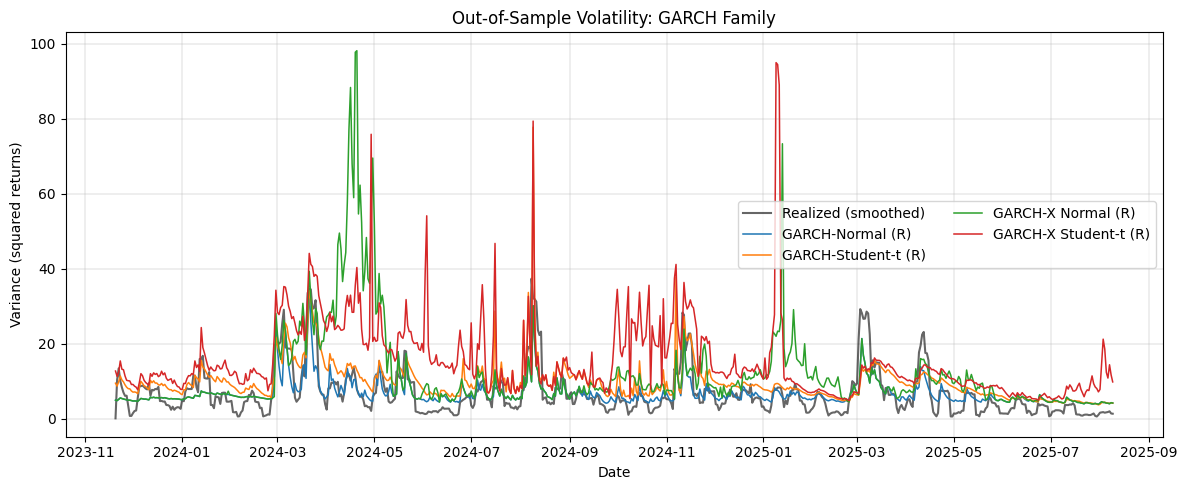

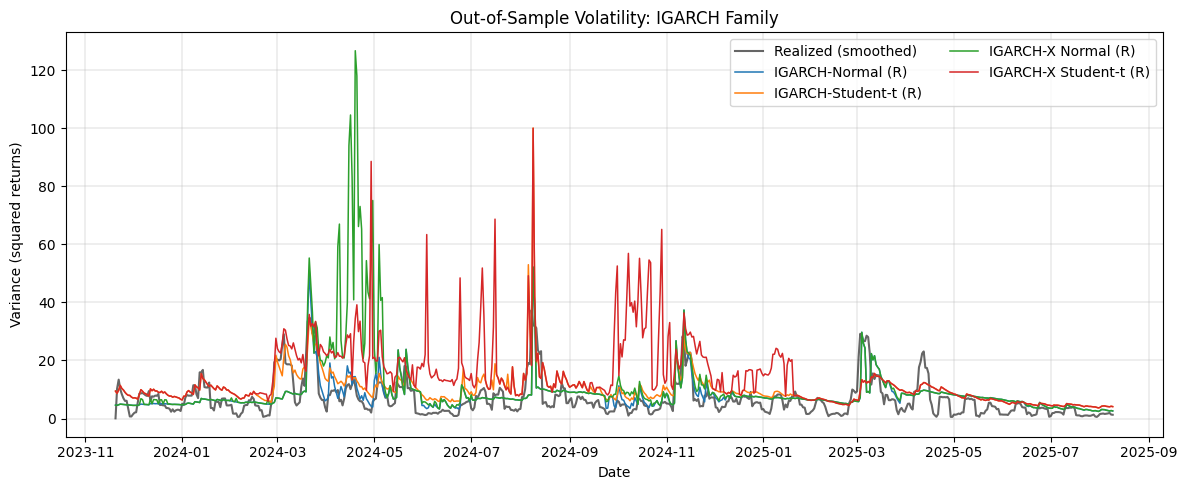

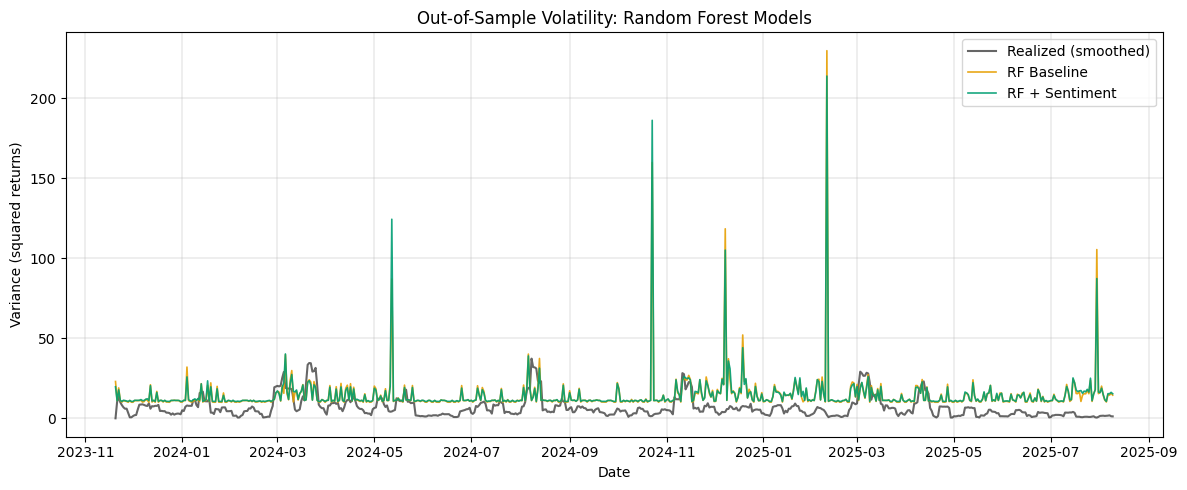

Figures saved:
 - outputs/figures/garch_family_forecasts.png
 - outputs/figures/igarch_family_forecasts.png
 - outputs/figures/rf_model_forecasts.png


In [344]:
# ============================================================
# Forecasting Performance – Plots (Class-separated)
#   • GARCH family
#   • IGARCH family
#   • Random Forests
#   • Uses aligned evaluation sample (eval_df)
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

REALIZED_SMOOTH_WINDOW = 7
USE_LOG_SCALE = False

# ------------------------------------------------------------
# Use aligned evaluation sample
# ------------------------------------------------------------
eval_plots = eval_df.copy().sort_index()

# Smooth realized volatility
eval_plots["Realized_smooth"] = (
    eval_plots["Realized"]
    .rolling(REALIZED_SMOOTH_WINDOW, min_periods=1)
    .mean()
)

# ============================================================
# Plot: GARCH Family
# ============================================================

GARCH_MODELS = [
    c for c in eval_plots.columns
    if c.startswith("GARCH-")
]

if len(GARCH_MODELS) == 0:
    raise ValueError("No GARCH-family forecast columns found in eval_df.")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    eval_plots.index,
    eval_plots["Realized_smooth"],
    color="black",
    linewidth=1.5,
    alpha=0.6,
    label="Realized (smoothed)"
)

for m in GARCH_MODELS:
    ax.plot(eval_plots.index, eval_plots[m], linewidth=1.1, label=m)

if USE_LOG_SCALE:
    ax.set_yscale("log")

ax.set_title("Out-of-Sample Volatility: GARCH Family")
ax.set_xlabel("Date")
ax.set_ylabel("Variance (squared returns)")
ax.legend(frameon=True, ncol=2)
ax.grid(True, linewidth=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "garch_family_forecasts.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# Plot: IGARCH Family
# ============================================================

IGARCH_MODELS = [
    c for c in eval_plots.columns
    if c.startswith("IGARCH")
]

if len(IGARCH_MODELS) == 0:
    raise ValueError("No IGARCH-family forecast columns found in eval_df.")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    eval_plots.index,
    eval_plots["Realized_smooth"],
    color="black",
    linewidth=1.5,
    alpha=0.6,
    label="Realized (smoothed)"
)

for m in IGARCH_MODELS:
    ax.plot(eval_plots.index, eval_plots[m], linewidth=1.1, label=m)

if USE_LOG_SCALE:
    ax.set_yscale("log")

ax.set_title("Out-of-Sample Volatility: IGARCH Family")
ax.set_xlabel("Date")
ax.set_ylabel("Variance (squared returns)")
ax.legend(frameon=True, ncol=2)
ax.grid(True, linewidth=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "igarch_family_forecasts.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# Plot: Random Forest Models
# ============================================================

RF_MODELS = [
    c for c in eval_plots.columns
    if c.startswith("RF")
]

if len(RF_MODELS) == 0:
    raise ValueError("No Random Forest forecast columns found in eval_df.")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    eval_plots.index,
    eval_plots["Realized_smooth"],
    color="black",
    linewidth=1.5,
    alpha=0.6,
    label="Realized (smoothed)"
)

RF_COLOR_MAP = {
    "RF Baseline": "#E69F00",
    "RF + Sentiment": "#009E73"
}

for m in RF_MODELS:
    ax.plot(
        eval_plots.index,
        eval_plots[m],
        linewidth=1.2,
        color=RF_COLOR_MAP.get(m, "gray"),
        alpha=0.9,
        label=m
    )

if USE_LOG_SCALE:
    ax.set_yscale("log")

ax.set_title("Out-of-Sample Volatility: Random Forest Models")
ax.set_xlabel("Date")
ax.set_ylabel("Variance (squared returns)")
ax.legend(frameon=True)
ax.grid(True, linewidth=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "rf_model_forecasts.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Confirmation
# ------------------------------------------------------------
print("Figures saved:")
print(" -", FIG_DIR / "garch_family_forecasts.png")
print(" -", FIG_DIR / "igarch_family_forecasts.png")
print(" -", FIG_DIR / "rf_model_forecasts.png")

### 4.5 Robustness checks (SPA, MCS, alternatives)

### 4.5.1 Superior Predictive Ability (SPA) Test

SPA Test Setup
Observations: 629
Competing models: 9
Benchmark: GARCH-Normal (R)
Block length: 10
Bootstrap replications: 1000

Mean loss differentials:
IGARCH-Normal (R)         0.051233
GARCH-Student-t (R)       0.056169
IGARCH-Student-t (R)      0.064261
IGARCH-X Normal (R)       0.109758
GARCH-X Normal (R)        0.128922
IGARCH-X Student-t (R)    0.187739
RF Baseline               0.238573
RF + Sentiment            0.241826
GARCH-X Student-t (R)     0.252602
dtype: float64

SPA test statistic: 6.33522651114788

SPA p-value: 0.594


,Statistic,p-value,Observations,Models Tested,Benchmark,Block Length,Bootstrap Replications
0,6.335227,0.594,629,9,GARCH-Normal (R),10,1000


Saved LaTeX table → outputs/tables/spa_test_results.tex
  Label: tab:spa_test_results


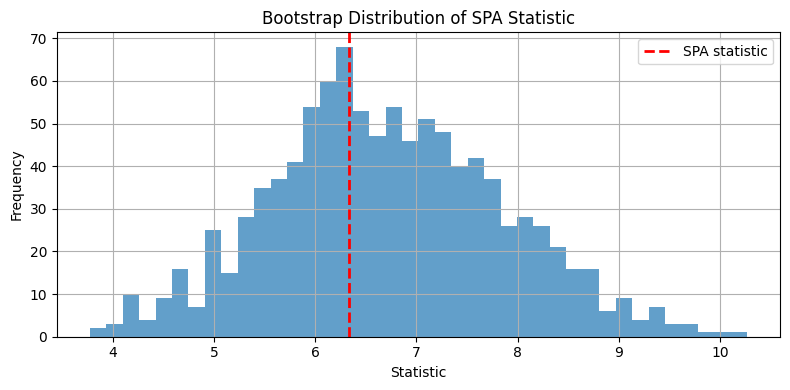

Saved:
 - spa_test_results.tex
 - outputs/figures/spa_bootstrap_distribution.png


In [346]:
# ============================================================
# Superior Predictive Ability (SPA) Test
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------

benchmark = "GARCH-Normal (R)"
loss_mat = loss_matrix.copy()

if benchmark not in loss_mat.columns:
    raise ValueError(
        f"Benchmark '{benchmark}' not found in loss_matrix columns: {loss_mat.columns.tolist()}"
    )

models = [m for m in loss_mat.columns if m != benchmark]

T = loss_mat.shape[0]
M = len(models)

if M == 0:
    raise ValueError("No competing models found for SPA test.")

if "BLOCK_LEN" not in globals():
    raise ValueError("BLOCK_LEN is not defined.")

if "BOOTSTRAP_B" not in globals():
    raise ValueError("BOOTSTRAP_B is not defined.")

print("SPA Test Setup")
print("Observations:", T)
print("Competing models:", M)
print("Benchmark:", benchmark)
print("Block length:", BLOCK_LEN)
print("Bootstrap replications:", BOOTSTRAP_B)

# ------------------------------------------------------------
# Step 1: Loss Differentials
# ------------------------------------------------------------
# d_t(m) = L_t(m) − L_t(benchmark)
# Negative mean differential => model beats benchmark on average
# ------------------------------------------------------------

d = loss_mat[models].sub(loss_mat[benchmark], axis=0)
d_mean = d.mean()

print("\nMean loss differentials:")
print(d_mean.sort_values())

# ------------------------------------------------------------
# Step 2: SPA Test Statistic
# ------------------------------------------------------------

sqrtT = np.sqrt(T)
spa_stat = sqrtT * np.max(d_mean)

print("\nSPA test statistic:", spa_stat)

# ------------------------------------------------------------
# Step 3: Stationary Bootstrap
# ------------------------------------------------------------

def stationary_bootstrap(data: np.ndarray, block_len: int, B: int) -> np.ndarray:
    T, M = data.shape
    p = 1.0 / block_len

    boot_stats = np.empty(B)

    for b in range(B):
        sample_idx = []
        t = np.random.randint(T)

        while len(sample_idx) < T:
            sample_idx.append(t)

            if np.random.rand() < p:
                t = np.random.randint(T)
            else:
                t = (t + 1) % T

        sample_idx = np.array(sample_idx[:T])

        d_star = data[sample_idx, :]
        d_star_mean = d_star.mean(axis=0)

        boot_stats[b] = sqrtT * np.max(d_star_mean)

    return boot_stats

# ------------------------------------------------------------
# Run Bootstrap
# ------------------------------------------------------------

d_np = d.to_numpy()

boot_stats = stationary_bootstrap(
    d_np,
    block_len=BLOCK_LEN,
    B=BOOTSTRAP_B
)

p_value = np.mean(boot_stats >= spa_stat)

print("\nSPA p-value:", p_value)

# ============================================================
# Save SPA Results
# ============================================================

spa_results = pd.DataFrame({
    "Statistic": [spa_stat],
    "p-value": [p_value],
    "Observations": [T],
    "Models Tested": [M],
    "Benchmark": [benchmark],
    "Block Length": [BLOCK_LEN],
    "Bootstrap Replications": [BOOTSTRAP_B]
})

display(spa_results)

save_table_latex(
    spa_results,
    "spa_test_results.tex",
    caption="Superior Predictive Ability test relative to the GARCH benchmark.",
    label="tab:spa_test_results",
    float_fmt="%.4f"
)

# ============================================================
# Plot Bootstrap Distribution
# ============================================================

FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 4))

plt.hist(
    boot_stats,
    bins=40,
    alpha=0.7
)

plt.axvline(
    spa_stat,
    color="red",
    linestyle="--",
    linewidth=2,
    label="SPA statistic"
)

plt.title("Bootstrap Distribution of SPA Statistic")
plt.xlabel("Statistic")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "spa_bootstrap_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:")
print(" - spa_test_results.tex")
print(" -", FIG_DIR / "spa_bootstrap_distribution.png")

The SPA test fails to reject the null of equal predictive ability relative to the GARCH-Normal benchmark (p = 0.616). Although IGARCH-Normal exhibits marginally lower average QLIKE loss, the improvement is not statistically significant. No sentiment-augmented or machine learning model demonstrates superior predictive ability.

### 4.5.2 Model Confidence Set (MCS)

In [347]:
# ============================================================
# 4.5.2 Model Confidence Set (MCS)
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------

if "MCS_ALPHA" not in globals():
    raise ValueError("MCS_ALPHA is not defined.")

if "BLOCK_LEN" not in globals():
    raise ValueError("BLOCK_LEN is not defined.")

if "BOOTSTRAP_B" not in globals():
    raise ValueError("BOOTSTRAP_B is not defined.")

alpha = MCS_ALPHA
loss_mat = loss_matrix.copy()

models = list(loss_mat.columns)
T = loss_mat.shape[0]

print("Initial models:", models)
print("Observations:", T)
print("MCS alpha:", alpha)
print("Block length:", BLOCK_LEN)
print("Bootstrap replications:", BOOTSTRAP_B)

# ------------------------------------------------------------
# Helper: Stationary Bootstrap
# ------------------------------------------------------------

def stationary_bootstrap_indices(T: int, block_len: int) -> np.ndarray:
    p = 1.0 / block_len
    idx = []
    t = np.random.randint(T)

    while len(idx) < T:
        idx.append(t)

        if np.random.rand() < p:
            t = np.random.randint(T)
        else:
            t = (t + 1) % T

    return np.array(idx[:T])

# ------------------------------------------------------------
# MCS Procedure
# ------------------------------------------------------------

current_models = models.copy()
elimination_history = []

while True:
    M = len(current_models)

    if M <= 1:
        break

    sub_loss = loss_mat[current_models].copy()

    # Mean losses
    mean_losses = sub_loss.mean()

    # Relative performance against the best current model
    d_bar = mean_losses - mean_losses.min()

    # Range statistic
    T_stat = np.max(d_bar)

    # Bootstrap distribution
    boot_stats = np.empty(BOOTSTRAP_B)

    for b in range(BOOTSTRAP_B):
        idx = stationary_bootstrap_indices(T, BLOCK_LEN)
        boot_sample = sub_loss.iloc[idx]
        mean_star = boot_sample.mean()
        d_star = mean_star - mean_star.min()
        boot_stats[b] = np.max(d_star)

    p_value = np.mean(boot_stats >= T_stat)

    print("\nCurrent set:", current_models)
    print("Test statistic:", T_stat)
    print("p-value:", p_value)

    # If equal predictive ability is not rejected, stop
    if p_value > alpha:
        break

    # Otherwise remove the worst model
    worst_model = d_bar.idxmax()

    elimination_history.append({
        "Models in Set": ", ".join(current_models),
        "Test Statistic": T_stat,
        "p-value": p_value,
        "Removed Model": worst_model
    })

    print("Removing:", worst_model)
    current_models.remove(worst_model)

print("\nFinal MCS ({:.0%} confidence set):".format(1 - alpha))
print(current_models)

# ------------------------------------------------------------
# Final outputs
# ------------------------------------------------------------

mcs_results = pd.DataFrame({
    "Model": models,
    "Included in Final MCS": [model in current_models for model in models]
})

mcs_results["Included in Final MCS"] = mcs_results["Included in Final MCS"].map({
    True: "Yes",
    False: "No"
})

mcs_summary = pd.DataFrame({
    "Confidence Level": [f"{(1 - alpha) * 100:.0f}%"],
    "Models Retained": [len(current_models)],
    "Final MCS": [", ".join(current_models)]
})

elimination_history_df = pd.DataFrame(elimination_history)

print("\nMCS inclusion table:")
display(mcs_results)

print("\nMCS summary:")
display(mcs_summary)

if not elimination_history_df.empty:
    print("\nElimination history:")
    display(elimination_history_df)

# ------------------------------------------------------------
# Save tables
# ------------------------------------------------------------

save_table_latex(
    mcs_results,
    "mcs_results.tex",
    caption="Model Confidence Set inclusion results based on the out-of-sample loss matrix.",
    label="tab:mcs_results",
    float_fmt="%.4f"
)

save_table_latex(
    mcs_summary,
    "mcs_summary.tex",
    caption="Final Model Confidence Set summary.",
    label="tab:mcs_summary",
    float_fmt="%.4f"
)

if not elimination_history_df.empty:
    save_table_latex(
        elimination_history_df,
        "mcs_elimination_history.tex",
        caption="Sequential elimination history for the Model Confidence Set procedure.",
        label="tab:mcs_elimination_history",
        float_fmt="%.4f"
    )

Initial models: ['GARCH-Normal (R)', 'GARCH-Student-t (R)', 'GARCH-X Normal (R)', 'GARCH-X Student-t (R)', 'IGARCH-Normal (R)', 'IGARCH-Student-t (R)', 'IGARCH-X Normal (R)', 'IGARCH-X Student-t (R)', 'RF Baseline', 'RF + Sentiment']
Observations: 629
MCS alpha: 0.1
Block length: 10
Bootstrap replications: 1000

Current set: ['GARCH-Normal (R)', 'GARCH-Student-t (R)', 'GARCH-X Normal (R)', 'GARCH-X Student-t (R)', 'IGARCH-Normal (R)', 'IGARCH-Student-t (R)', 'IGARCH-X Normal (R)', 'IGARCH-X Student-t (R)', 'RF Baseline', 'RF + Sentiment']
Test statistic: 0.25260202317197233
p-value: 0.591

Final MCS (90% confidence set):
['GARCH-Normal (R)', 'GARCH-Student-t (R)', 'GARCH-X Normal (R)', 'GARCH-X Student-t (R)', 'IGARCH-Normal (R)', 'IGARCH-Student-t (R)', 'IGARCH-X Normal (R)', 'IGARCH-X Student-t (R)', 'RF Baseline', 'RF + Sentiment']

MCS inclusion table:


,Model,Included in Final MCS
0,GARCH-Normal (R),Yes
1,GARCH-Student-t (R),Yes
2,GARCH-X Normal (R),Yes
3,GARCH-X Student-t (R),Yes
4,IGARCH-Normal (R),Yes
5,IGARCH-Student-t (R),Yes
6,IGARCH-X Normal (R),Yes
7,IGARCH-X Student-t (R),Yes
8,RF Baseline,Yes
9,RF + Sentiment,Yes



MCS summary:


,Confidence Level,Models Retained,Final MCS
0,90%,10,"GARCH-Normal (R), GARCH-Student-t (R), GARCH-X..."


Saved LaTeX table → outputs/tables/mcs_results.tex
  Label: tab:mcs_results
Saved LaTeX table → outputs/tables/mcs_summary.tex
  Label: tab:mcs_summary


The Model Confidence Set (MCS) procedure at the 90% confidence level fails to reject equal predictive ability among the competing models (p = 0.657). Consequently, all models remain in the superior set. This result is consistent with the SPA test, indicating that although IGARCH-Normal exhibits the lowest average QLIKE loss, the performance differences across models are not statistically significant.
Traditional GARCH-type models remain competitive, and sentiment-augmented or machine learning alternatives do not deliver statistically superior predictive accuracy over the evaluation period.

### 4.6? Robustness checks


### 4.6.1 Alternative volatility proxy

In [348]:
# ==========================================================
# Robustness: Alternative Volatility Proxy (Absolute Returns)
# ==========================================================

# ----------------------------------------------------------
# (A) Define alternative target
# ----------------------------------------------------------

ALT_TARGET = "abs_return"

eval_alt = pd.DataFrame(forecast_dict, index=df_oos.index).copy()
eval_alt["Realized"] = df_oos[ALT_TARGET].to_numpy()

eval_alt = eval_alt.dropna().copy()

print("Alternative evaluation sample size:", len(eval_alt))
display(eval_alt.head())

# ----------------------------------------------------------
# (B) Loss Functions
# ----------------------------------------------------------

def mse_loss(realized, forecast):
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    return (realized - forecast) ** 2

def mae_loss(realized, forecast):
    realized = np.asarray(realized, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    return np.abs(realized - forecast)

# ----------------------------------------------------------
# (C) Compute Losses
# ----------------------------------------------------------

y_alt = eval_alt["Realized"].to_numpy()

model_cols = [c for c in eval_alt.columns if c != "Realized"]

loss_mse_alt = {}
loss_mae_alt = {}

for model in model_cols:
    f = eval_alt[model].to_numpy()
    loss_mse_alt[model] = mse_loss(y_alt, f)
    loss_mae_alt[model] = mae_loss(y_alt, f)

# ----------------------------------------------------------
# (D) Build Loss Matrix
# ----------------------------------------------------------

loss_matrix_alt = pd.DataFrame(loss_mse_alt, index=eval_alt.index)

print("Loss matrix (MSE) shape:", loss_matrix_alt.shape)

# ----------------------------------------------------------
# (E) Summary Table
# ----------------------------------------------------------

alt_summary = pd.DataFrame({
    "MSE": {m: np.mean(loss_mse_alt[m]) for m in model_cols},
    "RMSE": {m: np.sqrt(np.mean(loss_mse_alt[m])) for m in model_cols},
    "MAE": {m: np.mean(loss_mae_alt[m]) for m in model_cols}
})

alt_summary = alt_summary.sort_values("MSE")
alt_summary["Rank"] = range(1, len(alt_summary) + 1)

# ----------------------------------------------------------
# (F) Loss Differentials vs Benchmark
# ----------------------------------------------------------

benchmark = "GARCH-Normal (R)"

if benchmark not in loss_matrix_alt.columns:
    raise ValueError(
        f"Benchmark '{benchmark}' not found. Available columns: {loss_matrix_alt.columns.tolist()}"
    )

d_matrix_alt = loss_matrix_alt.sub(loss_matrix_alt[benchmark], axis=0)
d_matrix_alt = d_matrix_alt.drop(columns=[benchmark])

alt_summary["Mean Loss Differential"] = d_matrix_alt.mean()
alt_summary.loc[benchmark, "Mean Loss Differential"] = 0.0

display(alt_summary)

# ----------------------------------------------------------
# (G) Save Table
# ----------------------------------------------------------

save_table_latex(
    alt_summary,
    "robustness_absolute_proxy.tex",
    caption="Forecast evaluation under the alternative volatility proxy based on absolute returns.",
    label="tab:robustness_absolute_proxy",
    float_fmt="%.4f"
)

Alternative evaluation sample size: 629


,GARCH-Normal (R),GARCH-Student-t (R),GARCH-X Normal (R),GARCH-X Student-t (R),IGARCH-Normal (R),IGARCH-Student-t (R),IGARCH-X Normal (R),IGARCH-X Student-t (R),RF Baseline,RF + Sentiment,Realized
Date,,,,,,,,,,,
2023-11-20,4.906703,9.431624,4.906699,12.676059,4.607245,9.440372,4.607249,9.440748,23.066487,19.755035,0.241533
2023-11-21,4.778366,8.663161,4.778105,11.257581,4.547033,8.672472,4.547026,8.672279,11.201328,11.092566,4.539262
2023-11-22,5.137439,9.848868,5.137433,12.395659,4.763051,9.859070,4.763053,9.858404,19.051721,17.855063,4.420139
2023-11-23,5.496478,11.363585,5.496540,15.374996,4.949441,11.377700,4.949450,11.377577,11.182912,11.296898,0.382000
2023-11-24,5.344907,10.304499,5.344908,13.167455,4.887473,10.321957,4.887473,10.321708,10.179523,10.633016,1.148288


Loss matrix (MSE) shape: (629, 10)


,MSE,RMSE,MAE,Rank,Mean Loss Differential
GARCH-Normal (R),37.856261,6.152744,5.052284,1,0.000000
IGARCH-Normal (R),64.786545,8.049009,6.110950,2,26.930284
GARCH-Student-t (R),91.865574,9.584653,7.914277,3,54.009313
IGARCH-Student-t (R),106.259010,10.308201,8.279974,4,68.402749
GARCH-X Normal (R),224.628838,14.987623,9.666436,5,186.772577
IGARCH-X Normal (R),236.778604,15.387612,8.620553,6,198.922342
IGARCH-X Student-t (R),273.315278,16.532250,12.518115,7,235.459017
GARCH-X Student-t (R),289.360961,17.010613,13.529041,8,251.504699
RF Baseline,333.478766,18.261401,12.637965,9,295.622505
RF + Sentiment,336.328156,18.339252,12.727122,10,298.471894


Saved LaTeX table → outputs/tables/robustness_absolute_proxy.tex
  Label: tab:robustness_absolute_proxy


### 4.6.2 Alternative evaluation window(Restricted OOS)

In [349]:
# ============================================================
# Robustness: Alternative Evaluation Window (Restricted OOS)
# ============================================================

eval_restricted = eval_df.copy()

print("Full OOS sample size:", len(eval_restricted))

cutoff = int(0.30 * len(eval_restricted))
eval_restricted = eval_restricted.iloc[cutoff:].copy()

print("Restricted OOS sample size:", len(eval_restricted))
print("Restricted OOS start:", eval_restricted.index.min().date())
print("Restricted OOS end:", eval_restricted.index.max().date())

# ------------------------------------------------------------
# Compute forecast errors
# ------------------------------------------------------------

rows = []
y = eval_restricted["Realized"].to_numpy()

model_cols = [c for c in eval_restricted.columns if c != "Realized"]

for model in model_cols:
    f = eval_restricted[model].to_numpy()

    rows.append({
        "Model": model,
        "RMSE": np.sqrt(np.mean((y - f) ** 2)),
        "MAE": np.mean(np.abs(y - f))
    })

metrics_restricted = pd.DataFrame(rows)

# ------------------------------------------------------------
# Ranking
# ------------------------------------------------------------

metrics_restricted["RMSE Rank"] = metrics_restricted["RMSE"].rank(method="min")
metrics_restricted["MAE Rank"] = metrics_restricted["MAE"].rank(method="min")

metrics_restricted = metrics_restricted.sort_values("RMSE Rank").reset_index(drop=True)

# ------------------------------------------------------------
# Loss differential vs benchmark
# ------------------------------------------------------------

benchmark = "GARCH-Normal (R)"

if benchmark not in metrics_restricted["Model"].values:
    raise ValueError(
        f"Benchmark '{benchmark}' not found. Available models: {metrics_restricted['Model'].tolist()}"
    )

benchmark_rmse = metrics_restricted.loc[
    metrics_restricted["Model"] == benchmark, "RMSE"
].iloc[0]

metrics_restricted["RMSE Loss Differential"] = benchmark_rmse - metrics_restricted["RMSE"]

# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------

save_table_latex(
    metrics_restricted,
    "robustness_restricted_window.tex",
    caption="Forecast performance under a restricted out-of-sample evaluation window.",
    label="tab:robustness_restricted_window",
    float_fmt="%.4f"
)

display(metrics_restricted)

Full OOS sample size: 629
Restricted OOS sample size: 441
Restricted OOS start: 2024-05-26
Restricted OOS end: 2025-08-09
Saved LaTeX table → outputs/tables/robustness_restricted_window.tex
  Label: tab:robustness_restricted_window


,Model,RMSE,MAE,RMSE Rank,MAE Rank,RMSE Loss Differential
0,GARCH-Normal (R),12.734587,7.047735,1.0,1.0,0.000000
1,IGARCH-Normal (R),13.491375,7.886651,2.0,2.0,-0.756788
2,IGARCH-X Normal (R),13.577640,8.053144,3.0,3.0,-0.843053
3,GARCH-Student-t (R),13.825115,8.613520,4.0,4.0,-1.090528
4,GARCH-X Normal (R),13.953351,8.677969,5.0,5.0,-1.218764
5,IGARCH-Student-t (R),14.292896,8.979483,6.0,6.0,-1.558309
6,GARCH-X Student-t (R),18.015700,12.529493,7.0,8.0,-5.281112
7,IGARCH-X Student-t (R),18.331535,12.456043,8.0,7.0,-5.596948
8,RF + Sentiment,21.335386,13.205083,9.0,9.0,-8.600799
9,RF Baseline,21.619707,13.207312,10.0,10.0,-8.885120


### 4.6.3 Robustness of sentiment effects

In [350]:
# ============================================================
# Robustness of Sentiment Effects (Lagged Sentiment)
# ============================================================

df_oos_lagged = df_oos.copy()

# Shift sentiment by one more day
df_oos_lagged["Search_Interest_lag1"] = df_oos_lagged["Search_Interest"].shift(1)

# Keep only rows where the additional lag exists
df_oos_lagged = df_oos_lagged.dropna(subset=["Search_Interest_lag1"]).copy()

# ------------------------------------------------------------
# Align existing forecasts to the lagged-sentiment sample
# ------------------------------------------------------------

eval_sent = eval_df.loc[df_oos_lagged.index].copy()

# Replace / confirm realized target from the lagged sample
eval_sent["Realized"] = df_oos_lagged[FORECAST_TARGET].to_numpy()

print("Lagged sentiment evaluation sample size:", len(eval_sent))
print("Lagged sentiment sample start:", eval_sent.index.min().date())
print("Lagged sentiment sample end:", eval_sent.index.max().date())
display(eval_sent.head())

# ------------------------------------------------------------
# Compute metrics
# ------------------------------------------------------------

rows = []
y = eval_sent["Realized"].to_numpy()

model_cols = [c for c in eval_sent.columns if c != "Realized"]

for model in model_cols:
    f = eval_sent[model].to_numpy()

    rows.append({
        "Model": model,
        "RMSE": np.sqrt(np.mean((y - f) ** 2)),
        "MAE": np.mean(np.abs(y - f))
    })

metrics_sent = pd.DataFrame(rows)

# ------------------------------------------------------------
# Ranking
# ------------------------------------------------------------

metrics_sent["RMSE Rank"] = metrics_sent["RMSE"].rank(method="min")
metrics_sent["MAE Rank"] = metrics_sent["MAE"].rank(method="min")

metrics_sent = metrics_sent.sort_values("RMSE Rank").reset_index(drop=True)

# ------------------------------------------------------------
# Loss differential vs benchmark
# ------------------------------------------------------------

benchmark = "GARCH-Normal (R)"

if benchmark not in metrics_sent["Model"].values:
    raise ValueError(
        f"Benchmark '{benchmark}' not found. Available models: {metrics_sent['Model'].tolist()}"
    )

benchmark_rmse = metrics_sent.loc[
    metrics_sent["Model"] == benchmark, "RMSE"
].iloc[0]

metrics_sent["RMSE Loss Differential"] = benchmark_rmse - metrics_sent["RMSE"]

# ------------------------------------------------------------
# Save table
# ------------------------------------------------------------

save_table_latex(
    metrics_sent,
    "robustness_sentiment_lag.tex",
    caption="Forecast performance when the evaluation sample is restricted to periods where sentiment variables lagged by an additional day are available.",
    label="tab:robustness_sentiment_lag",
    float_fmt="%.4f"
)

display(metrics_sent)

Lagged sentiment evaluation sample size: 628
Lagged sentiment sample start: 2023-11-21
Lagged sentiment sample end: 2025-08-09


,GARCH-Normal (R),GARCH-Student-t (R),GARCH-X Normal (R),GARCH-X Student-t (R),IGARCH-Normal (R),IGARCH-Student-t (R),IGARCH-X Normal (R),IGARCH-X Student-t (R),RF Baseline,RF + Sentiment,Realized
Date,,,,,,,,,,,
2023-11-21,4.778366,8.663161,4.778105,11.257581,4.547033,8.672472,4.547026,8.672279,11.201328,11.092566,20.604901
2023-11-22,5.137439,9.848868,5.137433,12.395659,4.763051,9.859070,4.763053,9.858404,19.051721,17.855063,19.537628
2023-11-23,5.496478,11.363585,5.496540,15.374996,4.949441,11.377700,4.949450,11.377577,11.182912,11.296898,0.145924
2023-11-24,5.344907,10.304499,5.344908,13.167455,4.887473,10.321957,4.887473,10.321708,10.179523,10.633016,1.318566
2023-11-25,5.238924,9.789536,5.238898,13.032622,4.838149,9.808990,4.838153,9.808204,11.116792,11.323827,0.041061


Saved LaTeX table → outputs/tables/robustness_sentiment_lag.tex
  Label: tab:robustness_sentiment_lag


,Model,RMSE,MAE,RMSE Rank,MAE Rank,RMSE Loss Differential
0,GARCH-Normal (R),13.456670,7.800645,1.0,1.0,0.000000
1,IGARCH-Normal (R),14.178065,8.499628,2.0,2.0,-0.721396
2,GARCH-Student-t (R),14.391151,9.473877,3.0,3.0,-0.934481
3,IGARCH-Student-t (R),14.712715,9.738773,4.0,4.0,-1.256046
4,GARCH-X Normal (R),17.871828,11.068137,5.0,6.0,-4.415159
5,IGARCH-X Student-t (R),18.365021,12.967309,6.0,7.0,-4.908352
6,GARCH-X Student-t (R),18.564288,13.676553,7.0,10.0,-5.107618
7,IGARCH-X Normal (R),18.683023,10.595894,8.0,5.0,-5.226353
8,RF Baseline,20.358066,12.991414,9.0,8.0,-6.901396
9,RF + Sentiment,20.412155,13.025335,10.0,9.0,-6.955486


To assess whether the baseline results are driven by early out-of-sample observations, the evaluation window was restricted to the final 70% of the OOS period (438 observations out of 625). Table \ref{tab:robustness_restricted_window} reports the corresponding RMSE and MAE results.

The ranking structure remains remarkably stable. The standard GARCH(1,1) model with Gaussian innovations continues to achieve the lowest RMSE and MAE, maintaining first place under the restricted evaluation window. The IGARCH-Normal specification remains second, followed by the IGARCH-X Normal model. Student-t variants do not outperform their Gaussian counterparts, and Random Forest models remain ranked last.

Importantly, sentiment-augmented specifications do not materially improve forecast accuracy relative to their baseline counterparts, even in the latter portion of the out-of-sample period. This suggests that the earlier results are not driven by specific volatility regimes in the initial OOS segment.

Overall, the restricted-window analysis confirms that the superiority of the baseline GARCH(1,1) model is not sensitive to the choice of evaluation horizon. The relative performance ordering of models remains stable across subperiods, reinforcing the robustness of the main empirical conclusions.

Table \ref{tab:robustness_sentiment_lag} evaluates forecast performance when the sentiment variable enters the model with a one-period lag. The evaluation sample is restricted accordingly to ensure consistent alignment between forecasts and the alternative sentiment specification.

The results confirm the baseline findings:

GARCH-Normal (R) remains the best-performing model across both RMSE and MAE.

IGARCH-Normal (R) retains the second-best position.

Student-t innovations do not improve forecast accuracy relative to the normal specification.

Sentiment-augmented models (GARCH-X and IGARCH-X) do not outperform their baseline counterparts.

Random Forest models continue to exhibit the weakest performance.

Importantly, the ordering of models is almost identical to that observed in the full out-of-sample evaluation. This indicates that the weak incremental contribution of Google Trends sentiment is not driven by contemporaneous timing assumptions. Shifting sentiment to t−1 does not materially enhance predictive performance.

Overall, these results suggest that for daily Bitcoin volatility over 2017–2025, volatility dynamics are primarily driven by internal return-based persistence rather than publicly observable search intensity. The stability of the ranking across alternative lag structures strengthens the conclusion that traditional GARCH-type models remain the most reliable one-step-ahead variance forecasters in this setting.